<a href="https://colab.research.google.com/github/rajivbandaru97/ModelGuard_Credit_risk_AI_MRM/blob/main/Modelguard_Credit_risk_AI_MRM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Initialisation

In [ ]:

# ModelGuard AI
## AI-Powered Model Risk Management and Regulatory Compliance Framework

### Project Objective

#ModelGuard AI is an intelligent governance platform designed to
#identify, assess and monitor documentation and regulatory compliance
#risks associated with credit risk models.

### Initial Scope

- Probability of Default (PD)
- Loss Given Default (LGD)
- Exposure at Default (EAD)

### Core Capabilities

1. Centralized Model Inventory
2. Model Risk Classification
3. Regulatory Control Mapping
4. Documentation Completeness Assessment
5. AI-Based Document Intelligence
6. Governance Findings and Remediation
7. Audit Trail and Reporting

### Technology Stack

Python | Pandas | NumPy | Scikit-learn |
PyTorch | TensorFlow | Plotly | SQLite

### Regulatory Reference

Basel Framework | RBI | ECB |
US Federal Reserve | EBA | IFRS 9

Note: Regulatory applicability and source-level traceability
will be established separately for each control.


# Install and Import libraries

In [ ]:

# ==========================================
# MODELguard AI - ENVIRONMENT CONFIGURATION
# ==========================================

!pip -q install pandas numpy scikit-learn \
    matplotlib seaborn plotly sqlalchemy \
    pydantic pyyaml openpyxl

# Import libraries

import os
import json
import hashlib
import warnings

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from datetime import datetime

from pathlib import Path
from sqlalchemy import create_engine

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report

warnings.filterwarnings("ignore")

# Reproducibility

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

print("ModelGuard AI environment initialized.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

ModelGuard AI environment initialized.
Pandas version: 2.2.3
NumPy version: 2.4.6


#Create Project Directories

In [ ]:

from google.colab import drive

drive.mount('/content/drive')

ValueError: Mountpoint must not already contain files

In [ ]:

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/ModelGuard_AI"
)

folders = [
    "data/raw",
    "data/processed",
    "data/synthetic",
    "models/pytorch",
    "models/tensorflow",
    "reports/compliance",
    "reports/validation",
    "reports/audit",
    "logs",
    "config"
]

for folder in folders:

    (PROJECT_ROOT / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("Project directories created.")

print("Project location:", PROJECT_ROOT)

Project directories created.
Project location: /content/drive/MyDrive/ModelGuard_AI


#Generating synthetic banking model inventory

#Generate Model Inventory

In [ ]:

# ==========================================
# SYNTHETIC CREDIT RISK MODEL INVENTORY
# ==========================================

model_types = ["PD", "LGD", "EAD"]

business_units = [
    "Retail Banking",
    "Corporate Banking",
    "SME Banking",
    "Wholesale Banking"
]

validation_statuses = [
    "Completed",
    "Pending",
    "Overdue",
    "Not Started"
]

development_statuses = [
    "Production",
    "Under Development",
    "Retired"
]

records = []

for i in range(1, 101):

    model_type = np.random.choice(model_types)

    record = {

        "model_id": f"CR-{model_type}-{i:03d}",

        "model_name": (
            f"{model_type} Risk Model {i:03d}"
        ),

        "model_type": model_type,

        "business_unit": np.random.choice(
            business_units
        ),

        "materiality_score": np.random.randint(1, 6),

        "complexity_score": np.random.randint(1, 6),

        "data_quality_score": np.random.randint(1, 6),

        "explainability_score": np.random.randint(1, 6),

        "regulatory_impact": np.random.randint(1, 6),

        "business_criticality": np.random.randint(1, 6),

        "third_party_dependency": np.random.randint(1, 6),

        "model_autonomy": np.random.randint(1, 6),

        "validation_status": np.random.choice(
            validation_statuses
        ),

        "development_status": np.random.choice(
            development_statuses,
            p=[0.75, 0.20, 0.05]
        ),

        "model_owner": np.random.choice([
            "Credit Risk",
            "Model Risk Management",
            "Quantitative Analytics",
            "Wholesale Risk"
        ]),

        "last_validation_date": pd.Timestamp(
            "2026-01-01"
        ) - pd.Timedelta(
            days=int(np.random.randint(0, 900))
        )

    }

    records.append(record)


inventory = pd.DataFrame(records)

inventory.head()


,model_id,model_name,model_type,business_unit,materiality_score,complexity_score,data_quality_score,explainability_score,regulatory_impact,business_criticality,third_party_dependency,model_autonomy,validation_status,development_status,model_owner,last_validation_date
0,CR-EAD-001,EAD Risk Model 001,EAD,Wholesale Banking,5,3,5,5,2,3,3,3,Not Started,Production,Wholesale Risk,2024-03-09
1,CR-EAD-002,EAD Risk Model 002,EAD,Corporate Banking,5,2,4,2,4,5,1,4,Pending,Production,Wholesale Risk,2023-08-29
2,CR-PD-003,PD Risk Model 003,PD,SME Banking,3,2,4,4,3,4,4,1,Overdue,Under Development,Quantitative Analytics,2025-12-12
3,CR-PD-004,PD Risk Model 004,PD,SME Banking,2,4,1,4,2,2,1,2,Completed,Production,Wholesale Risk,2024-12-31
4,CR-EAD-005,EAD Risk Model 005,EAD,Wholesale Banking,5,3,1,4,2,4,2,2,Not Started,Production,Quantitative Analytics,2024-11-26


#Data Quality assessments

In [ ]:

# ==========================================
# DATA QUALITY CHECKS
# ==========================================

print("Dataset Shape:", inventory.shape)

print("\nMissing Values:")
display(inventory.isnull().sum())

print("\nDuplicate Model IDs:")
print(inventory["model_id"].duplicated().sum())

score_columns = [
    "materiality_score",
    "complexity_score",
    "data_quality_score",
    "explainability_score",
    "regulatory_impact",
    "business_criticality"
]

assert inventory["model_id"].is_unique

assert inventory["model_type"].isin(
    ["PD", "LGD", "EAD"]
).all()

assert inventory[score_columns].apply(
    lambda col: col.between(1, 5).all()
).all()

assert inventory[score_columns].notna().all().all()

print("\nData quality checks passed.")

Dataset Shape: (100, 16)

Missing Values:


,0
model_id,0
model_name,0
model_type,0
business_unit,0
materiality_score,0
complexity_score,0
data_quality_score,0
explainability_score,0
regulatory_impact,0
business_criticality,0



Duplicate Model IDs:
0

Data quality checks passed.


#Model Risk Scoring

#Calculating Model risk

In [ ]:

# ==========================================
# MODEL RISK SCORING ENGINE
# ==========================================

def calculate_model_risk(row):

    score = (

        0.30 * row["materiality_score"] +

        0.25 * row["complexity_score"] +

        0.15 * row["regulatory_impact"] +

        0.10 * (
            6 - row["explainability_score"]
        ) +

        0.10 * (
            6 - row["data_quality_score"]
        ) +

        0.10 * row["business_criticality"]

    )

    return round(score * 20, 2)


inventory["risk_score"] = inventory.apply(
    calculate_model_risk,
    axis=1
)


def assign_risk_tier(score):

    if score >= 75:
        return "HIGH"

    elif score >= 50:
        return "MEDIUM"

    return "LOW"


inventory["risk_tier"] = (
    inventory["risk_score"].apply(
        assign_risk_tier
    )
)

display(
    inventory[
        [
            "model_id",
            "model_type",
            "risk_score",
            "risk_tier"
        ]
    ].head(15)
)

,model_id,model_type,risk_score,risk_tier
0,CR-EAD-001,EAD,61.0,MEDIUM
1,CR-EAD-002,EAD,74.0,MEDIUM
2,CR-PD-003,PD,53.0,MEDIUM
3,CR-PD-004,PD,56.0,MEDIUM
4,CR-EAD-005,EAD,73.0,MEDIUM
5,CR-LGD-006,LGD,43.0,LOW
6,CR-PD-007,PD,80.0,HIGH
7,CR-PD-008,PD,72.0,MEDIUM
8,CR-PD-009,PD,74.0,MEDIUM
9,CR-EAD-010,EAD,49.0,LOW


#Visualising risk distribution

In [ ]:

risk_distribution = (
    inventory["risk_tier"]
    .value_counts()
    .reset_index()
)

risk_distribution.columns = [
    "Risk Tier",
    "Number of Models"
]

fig = px.pie(
    risk_distribution,
    names="Risk Tier",
    values="Number of Models",
    title="Credit Risk Model Risk Distribution",
    hole=0.45
)

fig.show()


fig = px.box(
    inventory,
    x="model_type",
    y="risk_score",
    color="model_type",
    title="Risk Score Distribution by Model Type"
)

fig.show()

#REGULATORY CONTROL LIBRARY

#Create Initial Controls

In [ ]:

control_data = [

    ["MRM-001", "Inventory",
     "Complete model inventory",
     "Model Development Document"],

    ["MRM-002", "Ownership",
     "Documented model ownership",
     "Model Governance Policy"],

    ["MRM-003", "Development",
     "Documented methodology and assumptions",
     "Model Development Document"],

    ["MRM-004", "Validation",
     "Independent model validation",
     "Model Validation Report"],

    ["MRM-005", "Monitoring",
     "Ongoing model performance monitoring",
     "Model Monitoring Report"],

    ["MRM-006", "Approval",
     "Documented model approval",
     "Model Approval Document"],

    ["MRM-007", "Data Governance",
     "Documented data quality and lineage",
     "Data Quality Assessment Report"],

    ["MRM-008", "Limitations",
     "Documented model limitations",
     "Model Development Document"],

    ["MRM-009", "Change Management",
     "Documented model change history",
     "Model Change Request"],

    ["MRM-010", "Audit",
     "Documented remediation of findings",
     "Issue Remediation Register"]

]

control_library = pd.DataFrame(
    control_data,
    columns=[
        "control_id",
        "category",
        "requirement",
        "required_document"
    ]
)

display(control_library)

,control_id,category,requirement,required_document
0,MRM-001,Inventory,Complete model inventory,Model Development Document
1,MRM-002,Ownership,Documented model ownership,Model Governance Policy
2,MRM-003,Development,Documented methodology and assumptions,Model Development Document
3,MRM-004,Validation,Independent model validation,Model Validation Report
4,MRM-005,Monitoring,Ongoing model performance monitoring,Model Monitoring Report
5,MRM-006,Approval,Documented model approval,Model Approval Document
6,MRM-007,Data Governance,Documented data quality and lineage,Data Quality Assessment Report
7,MRM-008,Limitations,Documented model limitations,Model Development Document
8,MRM-009,Change Management,Documented model change history,Model Change Request
9,MRM-010,Audit,Documented remediation of findings,Issue Remediation Register


#DOCUMENTATION COMPLIANCE ASSISTANT

#Generate Document register

In [ ]:

document_types = control_library[
    "required_document"
].unique().tolist()

document_records = []

for model_id in inventory["model_id"]:

    for doc_type in document_types:

        # Synthetic documentation availability

        present = np.random.choice(
            [True, False],
            p=[0.75, 0.25]
        )

        if present:

            document_records.append({

                "model_id": model_id,

                "document_type": doc_type,

                "document_status": "Available",

                "version": "1.0",

                "approval_status": np.random.choice(
                    ["Approved", "Pending Review"]
                )

            })


document_register = pd.DataFrame(
    document_records
)

display(document_register.head(10))

print(
    "Total documents:",
    len(document_register)
)

,model_id,document_type,document_status,version,approval_status
0,CR-EAD-001,Model Development Document,Available,1.0,Pending Review
1,CR-EAD-001,Model Validation Report,Available,1.0,Approved
2,CR-EAD-001,Model Monitoring Report,Available,1.0,Approved
3,CR-EAD-001,Model Approval Document,Available,1.0,Approved
4,CR-EAD-001,Data Quality Assessment Report,Available,1.0,Approved
5,CR-EAD-002,Model Governance Policy,Available,1.0,Pending Review
6,CR-EAD-002,Model Validation Report,Available,1.0,Approved
7,CR-EAD-002,Model Monitoring Report,Available,1.0,Pending Review
8,CR-EAD-002,Model Approval Document,Available,1.0,Pending Review
9,CR-EAD-002,Data Quality Assessment Report,Available,1.0,Approved


Total documents: 601


#Compliance Engine

In [ ]:

# ==========================================
# DOCUMENTATION COMPLIANCE ENGINE
# ==========================================

def evaluate_model_compliance(
    model_id,
    controls,
    documents
):

    model_documents = set(
        documents.loc[
            documents["model_id"] == model_id,
            "document_type"
        ]
    )

    findings = []

    for _, control in controls.iterrows():

        required_doc = control["required_document"]

        if required_doc in model_documents:

            status = "EVIDENCE_PRESENT"

        else:

            status = "EVIDENCE_MISSING"

        findings.append({

            "model_id": model_id,

            "control_id": control["control_id"],

            "category": control["category"],

            "requirement": control["requirement"],

            "assessment_status": status

        })

    return findings


all_findings = []

for model_id in inventory["model_id"]:

    all_findings.extend(
        evaluate_model_compliance(
            model_id,
            control_library,
            document_register
        )
    )


compliance_results = pd.DataFrame(
    all_findings
)

display(compliance_results.head(20))

,model_id,control_id,category,requirement,assessment_status
0,CR-EAD-001,MRM-001,Inventory,Complete model inventory,EVIDENCE_PRESENT
1,CR-EAD-001,MRM-002,Ownership,Documented model ownership,EVIDENCE_MISSING
2,CR-EAD-001,MRM-003,Development,Documented methodology and assumptions,EVIDENCE_PRESENT
3,CR-EAD-001,MRM-004,Validation,Independent model validation,EVIDENCE_PRESENT
4,CR-EAD-001,MRM-005,Monitoring,Ongoing model performance monitoring,EVIDENCE_PRESENT
5,CR-EAD-001,MRM-006,Approval,Documented model approval,EVIDENCE_PRESENT
6,CR-EAD-001,MRM-007,Data Governance,Documented data quality and lineage,EVIDENCE_PRESENT
7,CR-EAD-001,MRM-008,Limitations,Documented model limitations,EVIDENCE_PRESENT
8,CR-EAD-001,MRM-009,Change Management,Documented model change history,EVIDENCE_MISSING
9,CR-EAD-001,MRM-010,Audit,Documented remediation of findings,EVIDENCE_MISSING


#Calculate Compliance Scores

In [ ]:

compliance_summary = (

    compliance_results

    .assign(
        evidence_present=lambda df:
        df["assessment_status"].eq(
            "EVIDENCE_PRESENT"
        )
    )

    .groupby("model_id")

    .agg(
        total_controls=("control_id", "count"),

        controls_satisfied=(
            "evidence_present",
            "sum"
        )
    )

    .reset_index()

)

compliance_summary["compliance_score"] = (

    compliance_summary["controls_satisfied"] /

    compliance_summary["total_controls"]

) * 100


compliance_summary = compliance_summary.merge(

    inventory[
        ["model_id", "model_name", "model_type", "risk_tier"]
    ],

    on="model_id",

    how="left"

)

display(
    compliance_summary.sort_values(
        "compliance_score"
    ).head(20)
)

,model_id,total_controls,controls_satisfied,compliance_score,model_name,model_type,risk_tier
10,CR-EAD-022,10,3,30.0,EAD Risk Model 022,EAD,LOW
59,CR-LGD-070,10,3,30.0,LGD Risk Model 070,LGD,LOW
9,CR-EAD-020,10,4,40.0,EAD Risk Model 020,EAD,MEDIUM
67,CR-LGD-095,10,4,40.0,LGD Risk Model 095,LGD,MEDIUM
96,CR-PD-082,10,4,40.0,PD Risk Model 082,PD,MEDIUM
83,CR-PD-049,10,4,40.0,PD Risk Model 049,PD,MEDIUM
71,CR-PD-008,10,4,40.0,PD Risk Model 008,PD,MEDIUM
28,CR-EAD-068,10,5,50.0,EAD Risk Model 068,EAD,HIGH
66,CR-LGD-094,10,5,50.0,LGD Risk Model 094,LGD,MEDIUM
82,CR-PD-048,10,5,50.0,PD Risk Model 048,PD,LOW


#GOVERNANCE REPORTING

#Identify Governance Exceptions

In [ ]:

governance_findings = compliance_results[
    compliance_results["assessment_status"]
    == "EVIDENCE_MISSING"
].copy()

governance_findings = governance_findings.merge(

    inventory[
        ["model_id", "risk_tier", "model_owner"]
    ],

    on="model_id",

    how="left"

)

governance_findings["severity"] = np.where(

    governance_findings["risk_tier"] == "HIGH",

    "HIGH",

    "MEDIUM"

)

governance_findings["recommended_action"] = (

    "Obtain and review the required documentation."

)

governance_findings["review_status"] = "PENDING_REVIEW"

display(
    governance_findings.head(20)
)

,model_id,control_id,category,requirement,assessment_status,risk_tier,model_owner,severity,recommended_action,review_status
0,CR-EAD-001,MRM-002,Ownership,Documented model ownership,EVIDENCE_MISSING,MEDIUM,Wholesale Risk,MEDIUM,Obtain and review the required documentation.,PENDING_REVIEW
1,CR-EAD-001,MRM-009,Change Management,Documented model change history,EVIDENCE_MISSING,MEDIUM,Wholesale Risk,MEDIUM,Obtain and review the required documentation.,PENDING_REVIEW
2,CR-EAD-001,MRM-010,Audit,Documented remediation of findings,EVIDENCE_MISSING,MEDIUM,Wholesale Risk,MEDIUM,Obtain and review the required documentation.,PENDING_REVIEW
3,CR-EAD-002,MRM-001,Inventory,Complete model inventory,EVIDENCE_MISSING,MEDIUM,Wholesale Risk,MEDIUM,Obtain and review the required documentation.,PENDING_REVIEW
4,CR-EAD-002,MRM-003,Development,Documented methodology and assumptions,EVIDENCE_MISSING,MEDIUM,Wholesale Risk,MEDIUM,Obtain and review the required documentation.,PENDING_REVIEW
5,CR-EAD-002,MRM-008,Limitations,Documented model limitations,EVIDENCE_MISSING,MEDIUM,Wholesale Risk,MEDIUM,Obtain and review the required documentation.,PENDING_REVIEW
6,CR-PD-004,MRM-005,Monitoring,Ongoing model performance monitoring,EVIDENCE_MISSING,MEDIUM,Wholesale Risk,MEDIUM,Obtain and review the required documentation.,PENDING_REVIEW
7,CR-PD-004,MRM-006,Approval,Documented model approval,EVIDENCE_MISSING,MEDIUM,Wholesale Risk,MEDIUM,Obtain and review the required documentation.,PENDING_REVIEW
8,CR-PD-004,MRM-007,Data Governance,Documented data quality and lineage,EVIDENCE_MISSING,MEDIUM,Wholesale Risk,MEDIUM,Obtain and review the required documentation.,PENDING_REVIEW
9,CR-EAD-005,MRM-004,Validation,Independent model validation,EVIDENCE_MISSING,MEDIUM,Quantitative Analytics,MEDIUM,Obtain and review the required documentation.,PENDING_REVIEW


#GOVERNANCE DASHBOARD

In [ ]:

fig = px.bar(

    compliance_summary.sort_values(
        "compliance_score"
    ),

    x="model_id",

    y="compliance_score",

    color="risk_tier",

    title="Documentation Completeness by Model",

    labels={
        "model_id": "Model ID",
        "compliance_score": "Completeness (%)"
    }

)

fig.update_layout(
    xaxis_tickangle=-45,
    height=600
)

fig.show()


severity_summary = (
    governance_findings["severity"]
    .value_counts()
    .reset_index()
)

severity_summary.columns = [
    "Severity",
    "Count"
]

fig = px.bar(
    severity_summary,
    x="Severity",
    y="Count",
    title="Outstanding Governance Findings"
)

fig.show()

#Extract Findings

In [ ]:

# ==========================================
# PHASE 1 OUTPUT EXPORT
# ==========================================

outputs = {

    "model_inventory.csv": inventory,

    "regulatory_control_library.csv": control_library,

    "document_register.csv": document_register,

    "compliance_results.csv": compliance_results,

    "compliance_summary.csv": compliance_summary,

    "governance_findings.csv": governance_findings

}

output_path = PROJECT_ROOT / "data" / "processed"

for filename, dataframe in outputs.items():

    dataframe.to_csv(
        output_path / filename,
        index=False
    )

    print("Saved:", filename)


print("\nPHASE 1 COMPLETED SUCCESSFULLY")

Saved: model_inventory.csv
Saved: regulatory_control_library.csv
Saved: document_register.csv
Saved: compliance_results.csv
Saved: compliance_summary.csv
Saved: governance_findings.csv

PHASE 1 COMPLETED SUCCESSFULLY


#Reload and inspect existing outputs

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from datetime import datetime, timezone
import json
import re
import hashlib

PROJECT_ROOT = Path("/content/drive/MyDrive/ModelGuard_AI")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
DOCUMENT_DIR = PROJECT_ROOT / "data" / "raw" / "model_documents"
DOCUMENT_DIR.mkdir(parents=True, exist_ok=True)

model_inventory = pd.read_csv(PROCESSED_DIR / "model_inventory.csv")
control_library = pd.read_csv(PROCESSED_DIR / "regulatory_control_library.csv")
document_register = pd.read_csv(PROCESSED_DIR / "document_register.csv")

print("Model inventory:", model_inventory.shape)
print("Control library:", control_library.shape)
print("Document register:", document_register.shape)

print("\nDocument register columns:")
print(document_register.columns.tolist())

print("\nControl library columns:")
print(control_library.columns.tolist())

display(document_register.head())
display(control_library.head())

Model inventory: (100, 18)
Control library: (10, 4)
Document register: (601, 5)

Document register columns:
['model_id', 'document_type', 'document_status', 'version', 'approval_status']

Control library columns:
['control_id', 'category', 'requirement', 'required_document']


,model_id,document_type,document_status,version,approval_status
0,CR-EAD-001,Model Development Document,Available,1.0,Pending Review
1,CR-EAD-001,Model Validation Report,Available,1.0,Approved
2,CR-EAD-001,Model Monitoring Report,Available,1.0,Approved
3,CR-EAD-001,Model Approval Document,Available,1.0,Approved
4,CR-EAD-001,Data Quality Assessment Report,Available,1.0,Approved


,control_id,category,requirement,required_document
0,MRM-001,Inventory,Complete model inventory,Model Development Document
1,MRM-002,Ownership,Documented model ownership,Model Governance Policy
2,MRM-003,Development,Documented methodology and assumptions,Model Development Document
3,MRM-004,Validation,Independent model validation,Model Validation Report
4,MRM-005,Monitoring,Ongoing model performance monitoring,Model Monitoring Report


#Standardise document register fields

In [ ]:
def find_column(df, candidates):
    for col in candidates:
        if col in df.columns:
            return col
    raise ValueError(
        f"Could not find any of these columns: {candidates}. "
        f"Available columns: {df.columns.tolist()}"
    )

MODEL_ID_COL = find_column(model_inventory, ["model_id", "Model_ID"])
CONTROL_ID_COL = find_column(control_library, ["control_id", "Control_ID"])

DOC_MODEL_COL = find_column(document_register, ["model_id", "Model_ID"])
DOC_TYPE_COL = find_column(
    document_register,
    ["document_type", "doc_type", "document_name", "document"]
)

DOC_STATUS_COL = find_column(
    document_register,
    ["document_status", "availability_status", "status"]
)

CONTROL_DOC_COL = find_column(
    control_library,
    ["required_document", "document_type", "required_doc"]
)

print("Detected fields:")
print({
    "model_id": DOC_MODEL_COL,
    "document_type": DOC_TYPE_COL,
    "document_status": DOC_STATUS_COL,
    "required_document": CONTROL_DOC_COL
})

Detected fields:
{'model_id': 'model_id', 'document_type': 'document_type', 'document_status': 'document_status', 'required_document': 'required_document'}


#Generate Synthetic Model Documentation

In [ ]:
rng = np.random.default_rng(42)

def make_document_content(model, doc_type, controls):
    model_id = model["model_id"]
    model_type = model["model_type"]

    sections = [
        f"Document Type: {doc_type}",
        f"Model ID: {model_id}",
        f"Model Type: {model_type}",
        f"Business Unit: {model['business_unit']}",
        f"Document Version: 1.0",
        f"Generated for ModelGuard AI synthetic testing."
    ]

    for _, control in controls.iterrows():

        control_id = control["control_id"]
        # Fixed: Using 'requirement' column since 'description' is not present in control_library
        description = str(control["requirement"])
        expected = str(control.get("expected_evidence", ""))

        # Deliberately introduce incomplete evidence in some test documents.
        omit_section = rng.random() < 0.20

        if omit_section:
            evidence_text = (
                f"{control_id}: Evidence section requires further "
                f"documentation and review."
            )
        else:
            evidence_text = (
                f"{control_id}: {description}. "
                f"Supporting documentation: {expected}. "
                f"The model owner is responsible for maintaining "
                f"the relevant records and supporting evidence. "
                f"This section is subject to independent review."
            )

        sections.append(evidence_text)

    sections.append(
        "Disclaimer: This is synthetic test documentation. "
        "It does not represent an actual financial institution, "
        "model approval, regulatory submission or compliance conclusion."
    )

    return "\n\n".join(sections)


# Standardise key fields for processing.
models = model_inventory.copy()
models["model_id"] = models[MODEL_ID_COL]

docs = document_register.copy()
docs["model_id"] = docs[DOC_MODEL_COL]
docs["document_type"] = docs[DOC_TYPE_COL]
docs["document_status"] = docs[DOC_STATUS_COL].astype(str)

controls = control_library.copy()
controls["control_id"] = controls[CONTROL_ID_COL]
controls["required_document"] = controls[CONTROL_DOC_COL]

# Generate content only for documents listed as available.
available_docs = docs[
    docs["document_status"].str.lower().isin(
        ["available", "present", "approved", "pending review"]
    )
].copy()

generated_documents = []

for _, doc in available_docs.iterrows():

    model_match = models[
        models["model_id"] == doc["model_id"]
    ]

    if model_match.empty:
        continue

    model = model_match.iloc[0]

    relevant_controls = controls[
        controls["required_document"].astype(str).str.lower()
        == str(doc["document_type"]).lower()
    ]

    content = make_document_content(
        model,
        doc["document_type"],
        relevant_controls
    )

    safe_doc_type = re.sub(
        r"[^A-Za-z0-9_-]+", "_", str(doc["document_type"])
    )

    file_name = f"{doc['model_id']}_{safe_doc_type}.txt"
    file_path = DOCUMENT_DIR / file_name

    file_path.write_text(content, encoding="utf-8")

    file_hash = hashlib.sha256(
        content.encode("utf-8")
    ).hexdigest()

    generated_documents.append({
        "model_id": doc["model_id"],
        "document_type": doc["document_type"],
        "file_name": file_name,
        "file_path": str(file_path),
        "document_hash": file_hash,
        "content_length": len(content),
        "synthetic_document": True
    })

synthetic_document_register = pd.DataFrame(generated_documents)

synthetic_document_register.to_csv(
    PROCESSED_DIR / "synthetic_document_register.csv",
    index=False
)

print("Synthetic documents generated:", len(synthetic_document_register))
display(synthetic_document_register.head())

Synthetic documents generated: 601


,model_id,document_type,file_name,file_path,document_hash,content_length,synthetic_document
0,CR-EAD-001,Model Development Document,CR-EAD-001_Model_Development_Document.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,985,True
1,CR-EAD-001,Model Validation Report,CR-EAD-001_Model_Validation_Report.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,07ed5315fd262529a28ff065d5364f55e49b178df9a7d6...,560,True
2,CR-EAD-001,Model Monitoring Report,CR-EAD-001_Model_Monitoring_Report.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,0aafdeab9ac4fbd2de6f9f2211f998b63070be4db875c5...,422,True
3,CR-EAD-001,Model Approval Document,CR-EAD-001_Model_Approval_Document.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,66eac91a85bceaff1c7416a54265fec455ed94a84380c4...,557,True
4,CR-EAD-001,Data Quality Assessment Report,CR-EAD-001_Data_Quality_Assessment_Report.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,21154f5a5937fe252817a2049ea99ed0eab9088f990e74...,574,True


#Extract Document sections into structured evidence

In [ ]:
evidence_records = []

for _, doc in synthetic_document_register.iterrows():

    file_path = Path(doc["file_path"])
    content = file_path.read_text(encoding="utf-8")

    paragraphs = [
        p.strip()
        for p in content.split("\n\n")
        if p.strip()
    ]

    for paragraph_number, paragraph in enumerate(paragraphs, start=1):

        control_match = re.match(
            r"(MRM-\d+):",
            paragraph
        )

        evidence_records.append({
            "model_id": doc["model_id"],
            "document_type": doc["document_type"],
            "file_name": doc["file_name"],
            "file_path": str(file_path),
            "paragraph_number": paragraph_number,
            "control_id_reference": (
                control_match.group(1)
                if control_match else None
            ),
            "evidence_text": paragraph,
            "document_hash": doc["document_hash"],
            "synthetic_evidence": True
        })

evidence_library = pd.DataFrame(evidence_records)

evidence_library.to_csv(
    PROCESSED_DIR / "evidence_library.csv",
    index=False
)

print("Evidence records extracted:", len(evidence_library))
display(evidence_library.head(10))

Evidence records extracted: 4948


,model_id,document_type,file_name,file_path,paragraph_number,control_id_reference,evidence_text,document_hash,synthetic_evidence
0,CR-EAD-001,Model Development Document,CR-EAD-001_Model_Development_Document.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,1,None,Document Type: Model Development Document,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,True
1,CR-EAD-001,Model Development Document,CR-EAD-001_Model_Development_Document.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,2,None,Model ID: CR-EAD-001,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,True
2,CR-EAD-001,Model Development Document,CR-EAD-001_Model_Development_Document.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,3,None,Model Type: EAD,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,True
3,CR-EAD-001,Model Development Document,CR-EAD-001_Model_Development_Document.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,4,None,Business Unit: Wholesale Banking,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,True
4,CR-EAD-001,Model Development Document,CR-EAD-001_Model_Development_Document.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,5,None,Document Version: 1.0,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,True
5,CR-EAD-001,Model Development Document,CR-EAD-001_Model_Development_Document.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,6,None,Generated for ModelGuard AI synthetic testing.,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,True
6,CR-EAD-001,Model Development Document,CR-EAD-001_Model_Development_Document.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,7,MRM-001,MRM-001: Complete model inventory. Supporting ...,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,True
7,CR-EAD-001,Model Development Document,CR-EAD-001_Model_Development_Document.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,8,MRM-003,MRM-003: Documented methodology and assumption...,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,True
8,CR-EAD-001,Model Development Document,CR-EAD-001_Model_Development_Document.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,9,MRM-008,MRM-008: Documented model limitations. Support...,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,True
9,CR-EAD-001,Model Development Document,CR-EAD-001_Model_Development_Document.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,10,None,Disclaimer: This is synthetic test documentati...,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,True


#Map evidence to governance control

In [ ]:
evidence_mappings = []

for _, model in models.iterrows():

    model_id = model["model_id"]

    for _, control in controls.iterrows():

        control_id = control["control_id"]

        candidates = evidence_library[
            (evidence_library["model_id"] == model_id) &
            (evidence_library["control_id_reference"] == control_id)
        ]

        if not candidates.empty:

            for _, evidence in candidates.iterrows():

                text_content = evidence["evidence_text"]

                incomplete = (
                    "requires further documentation"
                    in text_content.lower()
                )

                evidence_mappings.append({
                    "model_id": model_id,
                    "control_id": control_id,
                    "document_type": evidence["document_type"],
                    "file_name": evidence["file_name"],
                    "paragraph_number": evidence["paragraph_number"],
                    "evidence_text": text_content,
                    "document_hash": evidence["document_hash"],
                    "mapping_method": "EXPLICIT_CONTROL_ID",
                    "mapping_status": (
                        "CANDIDATE_INCOMPLETE"
                        if incomplete
                        else "CANDIDATE_FOUND"
                    ),
                    "human_review_status": "PENDING_REVIEW",
                    "synthetic_evidence": True
                })

evidence_mapping_df = pd.DataFrame(evidence_mappings)

evidence_mapping_df.to_csv(
    PROCESSED_DIR / "evidence_mappings.csv",
    index=False
)

print("Evidence mappings created:", len(evidence_mapping_df))
display(evidence_mapping_df.head(10))

Evidence mappings created: 741


,model_id,control_id,document_type,file_name,paragraph_number,evidence_text,document_hash,mapping_method,mapping_status,human_review_status,synthetic_evidence
0,CR-EAD-001,MRM-001,Model Development Document,CR-EAD-001_Model_Development_Document.txt,7,MRM-001: Complete model inventory. Supporting ...,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,EXPLICIT_CONTROL_ID,CANDIDATE_FOUND,PENDING_REVIEW,True
1,CR-EAD-001,MRM-003,Model Development Document,CR-EAD-001_Model_Development_Document.txt,8,MRM-003: Documented methodology and assumption...,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,EXPLICIT_CONTROL_ID,CANDIDATE_FOUND,PENDING_REVIEW,True
2,CR-EAD-001,MRM-004,Model Validation Report,CR-EAD-001_Model_Validation_Report.txt,7,MRM-004: Independent model validation. Support...,07ed5315fd262529a28ff065d5364f55e49b178df9a7d6...,EXPLICIT_CONTROL_ID,CANDIDATE_FOUND,PENDING_REVIEW,True
3,CR-EAD-001,MRM-005,Model Monitoring Report,CR-EAD-001_Model_Monitoring_Report.txt,7,MRM-005: Evidence section requires further doc...,0aafdeab9ac4fbd2de6f9f2211f998b63070be4db875c5...,EXPLICIT_CONTROL_ID,CANDIDATE_INCOMPLETE,PENDING_REVIEW,True
4,CR-EAD-001,MRM-006,Model Approval Document,CR-EAD-001_Model_Approval_Document.txt,7,MRM-006: Documented model approval. Supporting...,66eac91a85bceaff1c7416a54265fec455ed94a84380c4...,EXPLICIT_CONTROL_ID,CANDIDATE_FOUND,PENDING_REVIEW,True
5,CR-EAD-001,MRM-007,Data Quality Assessment Report,CR-EAD-001_Data_Quality_Assessment_Report.txt,7,MRM-007: Documented data quality and lineage. ...,21154f5a5937fe252817a2049ea99ed0eab9088f990e74...,EXPLICIT_CONTROL_ID,CANDIDATE_FOUND,PENDING_REVIEW,True
6,CR-EAD-001,MRM-008,Model Development Document,CR-EAD-001_Model_Development_Document.txt,9,MRM-008: Documented model limitations. Support...,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,EXPLICIT_CONTROL_ID,CANDIDATE_FOUND,PENDING_REVIEW,True
7,CR-EAD-002,MRM-002,Model Governance Policy,CR-EAD-002_Model_Governance_Policy.txt,7,MRM-002: Documented model ownership. Supportin...,04780687992dabc368a80cdd8d207eac167f7b8fff7cc5...,EXPLICIT_CONTROL_ID,CANDIDATE_FOUND,PENDING_REVIEW,True
8,CR-EAD-002,MRM-004,Model Validation Report,CR-EAD-002_Model_Validation_Report.txt,7,MRM-004: Evidence section requires further doc...,d0a94abb79ef5b5b25da1b04355aa851e3be80032c967f...,EXPLICIT_CONTROL_ID,CANDIDATE_INCOMPLETE,PENDING_REVIEW,True
9,CR-EAD-002,MRM-005,Model Monitoring Report,CR-EAD-002_Model_Monitoring_Report.txt,7,MRM-005: Ongoing model performance monitoring....,78fee2b63e28036bf980aa1682ecdfb9fe7f981e4fde1f...,EXPLICIT_CONTROL_ID,CANDIDATE_FOUND,PENDING_REVIEW,True


#Build evidence based assessment engine

In [ ]:
assessment_results = []

for _, model in models.iterrows():

    model_id = model["model_id"]

    for _, control in controls.iterrows():

        control_id = control["control_id"]

        candidates = evidence_mapping_df[
            (evidence_mapping_df["model_id"] == model_id) &
            (evidence_mapping_df["control_id"] == control_id)
        ]

        if candidates.empty:

            assessment_status = "NO_EVIDENCE_CANDIDATE"
            evidence_reference = None
            evidence_excerpt = None
            review_status = "PENDING_REVIEW"

        else:

            candidate = candidates.iloc[0]

            assessment_status = candidate["mapping_status"]
            evidence_reference = (
                f"{candidate['file_name']} | "
                f"Paragraph {candidate['paragraph_number']}"
            )
            evidence_excerpt = candidate["evidence_text"]
            review_status = "PENDING_REVIEW"

        assessment_results.append({
            "model_id": model_id,
            "control_id": control_id,
            "control_description": control["requirement"],
            "required_document": control["required_document"],
            "assessment_status": assessment_status,
            "evidence_reference": evidence_reference,
            "evidence_excerpt": evidence_excerpt,
            "human_review_status": review_status,
            "assessment_method": "DETERMINISTIC_BASELINE",
            "assessment_timestamp": datetime.now(timezone.utc).isoformat(),
            "synthetic_data": True
        })

evidence_assessment_df = pd.DataFrame(assessment_results)

evidence_assessment_df.to_csv(
    PROCESSED_DIR / "evidence_assessment_results.csv",
    index=False
)

print("Evidence assessments completed:", len(evidence_assessment_df))
display(evidence_assessment_df.head(15))

Evidence assessments completed: 1000


,model_id,control_id,control_description,required_document,assessment_status,evidence_reference,evidence_excerpt,human_review_status,assessment_method,assessment_timestamp,synthetic_data
0,CR-EAD-001,MRM-001,Complete model inventory,Model Development Document,CANDIDATE_FOUND,CR-EAD-001_Model_Development_Document.txt | Pa...,MRM-001: Complete model inventory. Supporting ...,PENDING_REVIEW,DETERMINISTIC_BASELINE,2026-11-17T10:31:35.029753+00:00,True
1,CR-EAD-001,MRM-002,Documented model ownership,Model Governance Policy,NO_EVIDENCE_CANDIDATE,None,None,PENDING_REVIEW,DETERMINISTIC_BASELINE,2026-11-17T10:31:35.030851+00:00,True
2,CR-EAD-001,MRM-003,Documented methodology and assumptions,Model Development Document,CANDIDATE_FOUND,CR-EAD-001_Model_Development_Document.txt | Pa...,MRM-003: Documented methodology and assumption...,PENDING_REVIEW,DETERMINISTIC_BASELINE,2026-11-17T10:31:35.032049+00:00,True
3,CR-EAD-001,MRM-004,Independent model validation,Model Validation Report,CANDIDATE_FOUND,CR-EAD-001_Model_Validation_Report.txt | Parag...,MRM-004: Independent model validation. Support...,PENDING_REVIEW,DETERMINISTIC_BASELINE,2026-11-17T10:31:35.033124+00:00,True
4,CR-EAD-001,MRM-005,Ongoing model performance monitoring,Model Monitoring Report,CANDIDATE_INCOMPLETE,CR-EAD-001_Model_Monitoring_Report.txt | Parag...,MRM-005: Evidence section requires further doc...,PENDING_REVIEW,DETERMINISTIC_BASELINE,2026-11-17T10:31:35.034178+00:00,True
5,CR-EAD-001,MRM-006,Documented model approval,Model Approval Document,CANDIDATE_FOUND,CR-EAD-001_Model_Approval_Document.txt | Parag...,MRM-006: Documented model approval. Supporting...,PENDING_REVIEW,DETERMINISTIC_BASELINE,2026-11-17T10:31:35.035259+00:00,True
6,CR-EAD-001,MRM-007,Documented data quality and lineage,Data Quality Assessment Report,CANDIDATE_FOUND,CR-EAD-001_Data_Quality_Assessment_Report.txt ...,MRM-007: Documented data quality and lineage. ...,PENDING_REVIEW,DETERMINISTIC_BASELINE,2026-11-17T10:31:35.036419+00:00,True
7,CR-EAD-001,MRM-008,Documented model limitations,Model Development Document,CANDIDATE_FOUND,CR-EAD-001_Model_Development_Document.txt | Pa...,MRM-008: Documented model limitations. Support...,PENDING_REVIEW,DETERMINISTIC_BASELINE,2026-11-17T10:31:35.037524+00:00,True
8,CR-EAD-001,MRM-009,Documented model change history,Model Change Request,NO_EVIDENCE_CANDIDATE,None,None,PENDING_REVIEW,DETERMINISTIC_BASELINE,2026-11-17T10:31:35.038497+00:00,True
9,CR-EAD-001,MRM-010,Documented remediation of findings,Issue Remediation Register,NO_EVIDENCE_CANDIDATE,None,None,PENDING_REVIEW,DETERMINISTIC_BASELINE,2026-11-17T10:31:35.039821+00:00,True


#Generate Evidence assessment summary

In [ ]:
assessment_summary = (
    evidence_assessment_df
    .groupby("assessment_status")
    .size()
    .reset_index(name="control_count")
)

assessment_summary["percentage"] = (
    assessment_summary["control_count"]
    / assessment_summary["control_count"].sum()
) * 100

display(assessment_summary)

fig = px.bar(
    assessment_summary,
    x="assessment_status",
    y="control_count",
    color="assessment_status",
    title="ModelGuard AI - Evidence Assessment Overview",
    text="control_count"
)

fig.update_layout(
    xaxis_title="Evidence Assessment Status",
    yaxis_title="Number of Controls",
    showlegend=False
)

fig.show()

,assessment_status,control_count,percentage
0,CANDIDATE_FOUND,580,58.0
1,CANDIDATE_INCOMPLETE,161,16.1
2,NO_EVIDENCE_CANDIDATE,259,25.9


#Model level evidence assessment dashboard

In [ ]:
model_evidence_summary = (
    evidence_assessment_df
    .groupby("model_id")
    .agg(
        total_controls=("control_id", "count"),
        candidate_found=(
            "assessment_status",
            lambda x: (x == "CANDIDATE_FOUND").sum()
        ),
        candidate_incomplete=(
            "assessment_status",
            lambda x: (x == "CANDIDATE_INCOMPLETE").sum()
        ),
        no_evidence_candidate=(
            "assessment_status",
            lambda x: (x == "NO_EVIDENCE_CANDIDATE").sum()
        )
    )
    .reset_index()
)

model_evidence_summary["evidence_candidate_rate"] = (
    model_evidence_summary["candidate_found"]
    / model_evidence_summary["total_controls"]
) * 100

model_evidence_summary.to_csv(
    PROCESSED_DIR / "model_evidence_assessment_summary.csv",
    index=False
)

display(
    model_evidence_summary.sort_values(
        "evidence_candidate_rate",
        ascending=True
    ).head(15)
)

fig = px.histogram(
    model_evidence_summary,
    x="evidence_candidate_rate",
    nbins=20,
    title="Distribution of Model Evidence Candidate Rates"
)

fig.update_layout(
    xaxis_title="Evidence Candidate Rate (%)",
    yaxis_title="Number of Models"
)

fig.show()

,model_id,total_controls,candidate_found,candidate_incomplete,no_evidence_candidate,evidence_candidate_rate
14,CR-EAD-036,10,2,8,0,20.0
10,CR-EAD-022,10,2,1,7,20.0
59,CR-LGD-070,10,2,1,7,20.0
70,CR-PD-007,10,2,3,5,20.0
8,CR-EAD-018,10,3,4,3,30.0
28,CR-EAD-068,10,3,2,5,30.0
9,CR-EAD-020,10,3,1,6,30.0
5,CR-EAD-013,10,3,3,4,30.0
87,CR-PD-061,10,3,4,3,30.0
83,CR-PD-049,10,3,1,6,30.0


#Install NLP libraries

In [ ]:
!pip -q install sentence-transformers scikit-learn

#Loading the Sentence Transformers

In [ ]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd
import re
from pathlib import Path

EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)

print("Embedding model loaded:", EMBEDDING_MODEL_NAME)
print("Embedding dimension:", embedding_model.get_sentence_embedding_dimension())

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded: sentence-transformers/all-MiniLM-L6-v2
Embedding dimension: 384


#Preparing the evidence corpus

In [ ]:
semantic_evidence = evidence_library.copy()

def clean_evidence_text(text):
    text = str(text)

    # Remove explicit control IDs so retrieval does not depend on them.
    text = re.sub(r"^MRM-\d+:\s*", "", text)

    return re.sub(r"\s+", " ", text).strip()


semantic_evidence["semantic_text"] = (
    semantic_evidence["evidence_text"]
    .apply(clean_evidence_text)
)

# Exclude document metadata and synthetic disclaimers.
excluded_prefixes = (
    "Document Type:",
    "Model ID:",
    "Model Type:",
    "Business Unit:",
    "Document Version:",
    "Generated for ModelGuard",
    "Disclaimer:"
)

semantic_evidence = semantic_evidence[
    ~semantic_evidence["semantic_text"].str.startswith(excluded_prefixes)
].copy()

# Remove empty or extremely short paragraphs.
semantic_evidence = semantic_evidence[
    semantic_evidence["semantic_text"].str.len() >= 30
].copy()

semantic_evidence = semantic_evidence.reset_index(drop=True)

print("Evidence paragraphs available for semantic search:",
      len(semantic_evidence))

display(
    semantic_evidence[
        ["model_id", "document_type", "paragraph_number", "semantic_text"]
    ].head(10)
)

Evidence paragraphs available for semantic search: 741


,model_id,document_type,paragraph_number,semantic_text
0,CR-EAD-001,Model Development Document,7,Complete model inventory. Supporting documenta...
1,CR-EAD-001,Model Development Document,8,Documented methodology and assumptions. Suppor...
2,CR-EAD-001,Model Development Document,9,Documented model limitations. Supporting docum...
3,CR-EAD-001,Model Validation Report,7,Independent model validation. Supporting docum...
4,CR-EAD-001,Model Monitoring Report,7,Evidence section requires further documentatio...
5,CR-EAD-001,Model Approval Document,7,Documented model approval. Supporting document...
6,CR-EAD-001,Data Quality Assessment Report,7,Documented data quality and lineage. Supportin...
7,CR-EAD-002,Model Governance Policy,7,Documented model ownership. Supporting documen...
8,CR-EAD-002,Model Validation Report,7,Evidence section requires further documentatio...
9,CR-EAD-002,Model Monitoring Report,7,Ongoing model performance monitoring. Supporti...


#Generate Embeddings

In [ ]:
evidence_texts = semantic_evidence["semantic_text"].tolist()

evidence_embeddings = embedding_model.encode(
    evidence_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

control_texts = controls["requirement"].astype(str).tolist()

control_embeddings = embedding_model.encode(
    control_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Evidence embedding shape:", evidence_embeddings.shape)
print("Control embedding shape:", control_embeddings.shape)

Batches:   0%|          | 0/24 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Evidence embedding shape: (741, 384)
Control embedding shape: (10, 384)


#Retrieving top 3 evidence candidates

In [ ]:
TOP_K = 3

semantic_matches = []

for model_id in models["model_id"].unique():

    model_evidence = semantic_evidence[
        semantic_evidence["model_id"] == model_id
    ].copy()

    if model_evidence.empty:
        continue

    evidence_indices = model_evidence.index.to_numpy()

    model_vectors = evidence_embeddings[evidence_indices]

    for control_index, control in controls.iterrows():

        query_vector = control_embeddings[control_index].reshape(1, -1)

        similarity_scores = cosine_similarity(
            query_vector,
            model_vectors
        )[0]

        top_positions = np.argsort(similarity_scores)[::-1][:TOP_K]

        for rank, position in enumerate(top_positions, start=1):

            evidence_row = model_evidence.iloc[position]
            similarity = float(similarity_scores[position])

            if similarity >= 0.60:
                match_category = "HIGH_SIMILARITY_CANDIDATE"
            elif similarity >= 0.40:
                match_category = "REVIEW_REQUIRED"
            else:
                match_category = "LOW_SIMILARITY_CANDIDATE"

            semantic_matches.append({
                "model_id": model_id,
                "control_id": control["control_id"],
                "control_description": control["requirement"],
                "candidate_rank": rank,
                "similarity_score": round(similarity, 4),
                "match_category": match_category,
                "document_type": evidence_row["document_type"],
                "file_name": evidence_row["file_name"],
                "paragraph_number": evidence_row["paragraph_number"],
                "evidence_text": evidence_row["semantic_text"],
                "document_hash": evidence_row["document_hash"],
                "review_status": "PENDING_HUMAN_REVIEW",
                "matching_method": "SENTENCE_TRANSFORMER_COSINE_SIMILARITY",
                "embedding_model": EMBEDDING_MODEL_NAME,
                "synthetic_evidence": True
            })

semantic_matches_df = pd.DataFrame(semantic_matches)

semantic_matches_df.to_csv(
    PROCESSED_DIR / "semantic_evidence_matches.csv",
    index=False
)

print("Semantic candidate matches generated:", len(semantic_matches_df))
display(
    semantic_matches_df.sort_values(
        ["model_id", "control_id", "candidate_rank"]
    ).head(15)
)

Semantic candidate matches generated: 3000


,model_id,control_id,control_description,candidate_rank,similarity_score,match_category,document_type,file_name,paragraph_number,evidence_text,document_hash,review_status,matching_method,embedding_model,synthetic_evidence
0,CR-EAD-001,MRM-001,Complete model inventory,1,0.7504,HIGH_SIMILARITY_CANDIDATE,Model Development Document,CR-EAD-001_Model_Development_Document.txt,7,Complete model inventory. Supporting documenta...,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,PENDING_HUMAN_REVIEW,SENTENCE_TRANSFORMER_COSINE_SIMILARITY,sentence-transformers/all-MiniLM-L6-v2,True
1,CR-EAD-001,MRM-001,Complete model inventory,2,0.4361,REVIEW_REQUIRED,Model Approval Document,CR-EAD-001_Model_Approval_Document.txt,7,Documented model approval. Supporting document...,66eac91a85bceaff1c7416a54265fec455ed94a84380c4...,PENDING_HUMAN_REVIEW,SENTENCE_TRANSFORMER_COSINE_SIMILARITY,sentence-transformers/all-MiniLM-L6-v2,True
2,CR-EAD-001,MRM-001,Complete model inventory,3,0.3887,LOW_SIMILARITY_CANDIDATE,Model Development Document,CR-EAD-001_Model_Development_Document.txt,9,Documented model limitations. Supporting docum...,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,PENDING_HUMAN_REVIEW,SENTENCE_TRANSFORMER_COSINE_SIMILARITY,sentence-transformers/all-MiniLM-L6-v2,True
3,CR-EAD-001,MRM-002,Documented model ownership,1,0.7733,HIGH_SIMILARITY_CANDIDATE,Model Development Document,CR-EAD-001_Model_Development_Document.txt,8,Documented methodology and assumptions. Suppor...,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,PENDING_HUMAN_REVIEW,SENTENCE_TRANSFORMER_COSINE_SIMILARITY,sentence-transformers/all-MiniLM-L6-v2,True
4,CR-EAD-001,MRM-002,Documented model ownership,2,0.7213,HIGH_SIMILARITY_CANDIDATE,Model Approval Document,CR-EAD-001_Model_Approval_Document.txt,7,Documented model approval. Supporting document...,66eac91a85bceaff1c7416a54265fec455ed94a84380c4...,PENDING_HUMAN_REVIEW,SENTENCE_TRANSFORMER_COSINE_SIMILARITY,sentence-transformers/all-MiniLM-L6-v2,True
5,CR-EAD-001,MRM-002,Documented model ownership,3,0.6865,HIGH_SIMILARITY_CANDIDATE,Model Development Document,CR-EAD-001_Model_Development_Document.txt,9,Documented model limitations. Supporting docum...,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,PENDING_HUMAN_REVIEW,SENTENCE_TRANSFORMER_COSINE_SIMILARITY,sentence-transformers/all-MiniLM-L6-v2,True
6,CR-EAD-001,MRM-003,Documented methodology and assumptions,1,0.6380,HIGH_SIMILARITY_CANDIDATE,Model Development Document,CR-EAD-001_Model_Development_Document.txt,8,Documented methodology and assumptions. Suppor...,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,PENDING_HUMAN_REVIEW,SENTENCE_TRANSFORMER_COSINE_SIMILARITY,sentence-transformers/all-MiniLM-L6-v2,True
7,CR-EAD-001,MRM-003,Documented methodology and assumptions,2,0.4685,REVIEW_REQUIRED,Model Development Document,CR-EAD-001_Model_Development_Document.txt,9,Documented model limitations. Supporting docum...,9466a7e9f90adf5e46ecf129ca49fa1bebff03dd9ff9ae...,PENDING_HUMAN_REVIEW,SENTENCE_TRANSFORMER_COSINE_SIMILARITY,sentence-transformers/all-MiniLM-L6-v2,True
8,CR-EAD-001,MRM-003,Documented methodology and assumptions,3,0.4608,REVIEW_REQUIRED,Model Monitoring Report,CR-EAD-001_Model_Monitoring_Report.txt,7,Evidence section requires further documentatio...,0aafdeab9ac4fbd2de6f9f2211f998b63070be4db875c5...,PENDING_HUMAN_REVIEW,SENTENCE_TRANSFORMER_COSINE_SIMILARITY,sentence-transformers/all-MiniLM-L6-v2,True
9,CR-EAD-001,MRM-004,Independent model validation,1,0.7987,HIGH_SIMILARITY_CANDIDATE,Model Validation Report,CR-EAD-001_Model_Validation_Report.txt,7,Independent model validation. Supporting docum...,07ed5315fd262529a28ff065d5364f55e49b178df9a7d6...,PENDING_HUMAN_REVIEW,SENTENCE_TRANSFORMER_COSINE_SIMILARITY,sentence-transformers/all-MiniLM-L6-v2,True


#Create a semantic matching summary

In [ ]:
semantic_summary = (
    semantic_matches_df
    .groupby("match_category")
    .size()
    .reset_index(name="candidate_count")
)

semantic_summary["percentage"] = (
    semantic_summary["candidate_count"]
    / semantic_summary["candidate_count"].sum()
) * 100

display(semantic_summary)

fig = px.bar(
    semantic_summary,
    x="match_category",
    y="candidate_count",
    color="match_category",
    text="candidate_count",
    title="ModelGuard AI - Semantic Evidence Matching"
)

fig.update_layout(
    xaxis_title="Candidate Match Category",
    yaxis_title="Number of Evidence Candidates",
    showlegend=False
)

fig.show()

,match_category,candidate_count,percentage
0,HIGH_SIMILARITY_CANDIDATE,1034,34.466667
1,LOW_SIMILARITY_CANDIDATE,288,9.600000
2,REVIEW_REQUIRED,1678,55.933333


#Build control level evidence review queue

In [ ]:
review_queue = (
    semantic_matches_df[
        semantic_matches_df["candidate_rank"] == 1
    ]
    .copy()
)

review_queue["review_decision"] = "AWAITING_REVIEW"
review_queue["reviewer_comments"] = ""
review_queue["reviewer_id"] = None
review_queue["review_timestamp"] = None

review_queue.to_csv(
    PROCESSED_DIR / "semantic_evidence_review_queue.csv",
    index=False
)

display(
    review_queue[
        [
            "model_id",
            "control_id",
            "similarity_score",
            "match_category",
            "document_type",
            "paragraph_number",
            "review_decision"
        ]
    ].head(20)
)

,model_id,control_id,similarity_score,match_category,document_type,paragraph_number,review_decision
0,CR-EAD-001,MRM-001,0.7504,HIGH_SIMILARITY_CANDIDATE,Model Development Document,7,AWAITING_REVIEW
3,CR-EAD-001,MRM-002,0.7733,HIGH_SIMILARITY_CANDIDATE,Model Development Document,8,AWAITING_REVIEW
6,CR-EAD-001,MRM-003,0.6380,HIGH_SIMILARITY_CANDIDATE,Model Development Document,8,AWAITING_REVIEW
9,CR-EAD-001,MRM-004,0.7987,HIGH_SIMILARITY_CANDIDATE,Model Validation Report,7,AWAITING_REVIEW
12,CR-EAD-001,MRM-005,0.4323,REVIEW_REQUIRED,Model Development Document,7,AWAITING_REVIEW
15,CR-EAD-001,MRM-006,0.8548,HIGH_SIMILARITY_CANDIDATE,Model Approval Document,7,AWAITING_REVIEW
18,CR-EAD-001,MRM-007,0.8119,HIGH_SIMILARITY_CANDIDATE,Data Quality Assessment Report,7,AWAITING_REVIEW
21,CR-EAD-001,MRM-008,0.8313,HIGH_SIMILARITY_CANDIDATE,Model Development Document,9,AWAITING_REVIEW
24,CR-EAD-001,MRM-009,0.5622,REVIEW_REQUIRED,Model Development Document,9,AWAITING_REVIEW
27,CR-EAD-001,MRM-010,0.4972,REVIEW_REQUIRED,Model Monitoring Report,7,AWAITING_REVIEW


#Inspect Strongest and Weakest Matches

In [ ]:
strongest_matches = semantic_matches_df.sort_values(
    "similarity_score",
    ascending=False
).head(10)

weakest_matches = semantic_matches_df.sort_values(
    "similarity_score",
    ascending=True
).head(10)

print("TOP 10 SEMANTIC MATCHES")
display(
    strongest_matches[
        [
            "model_id",
            "control_id",
            "similarity_score",
            "evidence_text"
        ]
    ]
)

print("BOTTOM 10 SEMANTIC MATCHES")
display(
    weakest_matches[
        [
            "model_id",
            "control_id",
            "similarity_score",
            "evidence_text"
        ]
    ]
)

TOP 10 SEMANTIC MATCHES


,model_id,control_id,similarity_score,evidence_text
2883,CR-EAD-097,MRM-002,0.8666,Documented model ownership. Supporting documen...
2973,CR-EAD-100,MRM-002,0.8666,Documented model ownership. Supporting documen...
2793,CR-LGD-094,MRM-002,0.8666,Documented model ownership. Supporting documen...
753,CR-EAD-026,MRM-002,0.8666,Documented model ownership. Supporting documen...
1953,CR-PD-066,MRM-002,0.8666,Documented model ownership. Supporting documen...
1893,CR-PD-064,MRM-002,0.8666,Documented model ownership. Supporting documen...
1983,CR-PD-067,MRM-002,0.8666,Documented model ownership. Supporting documen...
783,CR-LGD-027,MRM-002,0.8666,Documented model ownership. Supporting documen...
813,CR-LGD-028,MRM-002,0.8666,Documented model ownership. Supporting documen...
2763,CR-PD-093,MRM-002,0.8666,Documented model ownership. Supporting documen...


BOTTOM 10 SEMANTIC MATCHES


,model_id,control_id,similarity_score,evidence_text
2084,CR-LGD-070,MRM-005,0.0633,Evidence section requires further documentatio...
194,CR-PD-007,MRM-005,0.0633,Evidence section requires further documentatio...
644,CR-EAD-022,MRM-005,0.0633,Evidence section requires further documentatio...
1064,CR-EAD-036,MRM-005,0.0633,Evidence section requires further documentatio...
1052,CR-EAD-036,MRM-001,0.0937,Evidence section requires further documentatio...
632,CR-EAD-022,MRM-001,0.0937,Evidence section requires further documentatio...
2072,CR-LGD-070,MRM-001,0.0937,Evidence section requires further documentatio...
182,CR-PD-007,MRM-001,0.0937,Evidence section requires further documentatio...
191,CR-PD-007,MRM-004,0.1506,Evidence section requires further documentatio...
2081,CR-LGD-070,MRM-004,0.1506,Evidence section requires further documentatio...


#Basic quality checks

In [ ]:
assert not semantic_matches_df.empty, "No semantic matches generated."

assert semantic_matches_df["similarity_score"].between(
    -1, 1
).all(), "Similarity scores outside expected range."

assert semantic_matches_df["review_status"].eq(
    "PENDING_HUMAN_REVIEW"
).all(), "Unexpected review status."

assert semantic_matches_df["document_hash"].notna().all(), (
    "Some evidence candidates have no document hash."
)

assert semantic_matches_df["model_id"].isin(
    models["model_id"]
).all(), "Unexpected model ID."

print("All semantic matching quality checks passed.")

All semantic matching quality checks passed.


#CROSS DOCUMENT-INCOSISTENCY DETECTION

#Initialise inconsistency detection modules

In [ ]:
import pandas as pd
import numpy as np
import re
import json
from pathlib import Path
from datetime import datetime, timezone

PROJECT_ROOT = Path("/content/drive/MyDrive/ModelGuard_AI")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

models = pd.read_csv(PROCESSED_DIR / "model_inventory.csv")
synthetic_document_register = pd.read_csv(
    PROCESSED_DIR / "synthetic_document_register.csv"
)

print("Models:", len(models))
print("Documents:", len(synthetic_document_register))

Models: 100
Documents: 601


#Extract Metadata from every document

In [ ]:
def extract_document_metadata(file_path):

    text = Path(file_path).read_text(encoding="utf-8")

    def extract(pattern):
        match = re.search(pattern, text, flags=re.IGNORECASE)
        return match.group(1).strip() if match else None

    return {
        "extracted_model_id": extract(r"Model ID:\s*(.+)"),
        "extracted_model_type": extract(r"Model Type:\s*(.+)"),
        "extracted_business_unit": extract(r"Business Unit:\s*(.+)"),
        "extracted_document_version": extract(r"Document Version:\s*(.+)")
    }


metadata_records = []

for _, doc in synthetic_document_register.iterrows():

    extracted = extract_document_metadata(doc["file_path"])

    metadata_records.append({
        "model_id": doc["model_id"],
        "document_type": doc["document_type"],
        "file_name": doc["file_name"],
        "file_path": doc["file_path"],
        **extracted
    })

document_metadata_df = pd.DataFrame(metadata_records)

document_metadata_df.to_csv(
    PROCESSED_DIR / "document_metadata_extracted.csv",
    index=False
)

display(document_metadata_df.head(10))

,model_id,document_type,file_name,file_path,extracted_model_id,extracted_model_type,extracted_business_unit,extracted_document_version
0,CR-EAD-001,Model Development Document,CR-EAD-001_Model_Development_Document.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,CR-EAD-001,EAD,Wholesale Banking,1.0
1,CR-EAD-001,Model Validation Report,CR-EAD-001_Model_Validation_Report.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,CR-EAD-001,EAD,Wholesale Banking,1.0
2,CR-EAD-001,Model Monitoring Report,CR-EAD-001_Model_Monitoring_Report.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,CR-EAD-001,EAD,Wholesale Banking,1.0
3,CR-EAD-001,Model Approval Document,CR-EAD-001_Model_Approval_Document.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,CR-EAD-001,EAD,Wholesale Banking,1.0
4,CR-EAD-001,Data Quality Assessment Report,CR-EAD-001_Data_Quality_Assessment_Report.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,CR-EAD-001,EAD,Wholesale Banking,1.0
5,CR-EAD-002,Model Governance Policy,CR-EAD-002_Model_Governance_Policy.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,CR-EAD-002,EAD,Corporate Banking,1.0
6,CR-EAD-002,Model Validation Report,CR-EAD-002_Model_Validation_Report.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,CR-EAD-002,EAD,Corporate Banking,1.0
7,CR-EAD-002,Model Monitoring Report,CR-EAD-002_Model_Monitoring_Report.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,CR-EAD-002,EAD,Corporate Banking,1.0
8,CR-EAD-002,Model Approval Document,CR-EAD-002_Model_Approval_Document.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,CR-EAD-002,EAD,Corporate Banking,1.0
9,CR-EAD-002,Data Quality Assessment Report,CR-EAD-002_Data_Quality_Assessment_Report.txt,/content/drive/MyDrive/ModelGuard_AI/data/raw/...,CR-EAD-002,EAD,Corporate Banking,1.0


#Compare Document Metadata vs Model inventory

In [ ]:
inventory_lookup = models.set_index("model_id").to_dict("index")

metadata_findings = []

for _, doc in document_metadata_df.iterrows():

    model_id = doc["model_id"]

    if model_id not in inventory_lookup:
        metadata_findings.append({
            "model_id": model_id,
            "document_type": doc["document_type"],
            "finding_type": "MODEL_NOT_IN_INVENTORY",
            "field_name": "model_id",
            "inventory_value": None,
            "document_value": doc["extracted_model_id"],
            "severity": "HIGH"
        })
        continue

    inventory_record = inventory_lookup[model_id]

    comparisons = [
        ("model_id", "model_id", "extracted_model_id"),
        ("model_type", "model_type", "extracted_model_type"),
        ("business_unit", "business_unit", "extracted_business_unit")
    ]

    for field, inventory_field, document_field in comparisons:

        inventory_value = inventory_record.get(inventory_field)
        document_value = doc.get(document_field)

        if pd.isna(document_value) or document_value is None:
            continue

        if str(inventory_value).strip().lower() != str(document_value).strip().lower():

            metadata_findings.append({
                "model_id": model_id,
                "document_type": doc["document_type"],
                "finding_type": "METADATA_MISMATCH",
                "field_name": field,
                "inventory_value": str(inventory_value),
                "document_value": str(document_value),
                "severity": "HIGH" if field == "model_id" else "MEDIUM"
            })

metadata_findings_df = pd.DataFrame(metadata_findings)

if metadata_findings_df.empty:
    metadata_findings_df = pd.DataFrame(columns=[
        "model_id", "document_type", "finding_type",
        "field_name", "inventory_value", "document_value", "severity"
    ])

metadata_findings_df.to_csv(
    PROCESSED_DIR / "metadata_consistency_findings.csv",
    index=False
)

print("Metadata inconsistencies detected:", len(metadata_findings_df))
display(metadata_findings_df.head(20))

Metadata inconsistencies detected: 601


,model_id,document_type,finding_type,field_name,inventory_value,document_value,severity
0,CR-EAD-001,Model Development Document,METADATA_MISMATCH,model_id,None,CR-EAD-001,HIGH
1,CR-EAD-001,Model Validation Report,METADATA_MISMATCH,model_id,None,CR-EAD-001,HIGH
2,CR-EAD-001,Model Monitoring Report,METADATA_MISMATCH,model_id,None,CR-EAD-001,HIGH
3,CR-EAD-001,Model Approval Document,METADATA_MISMATCH,model_id,None,CR-EAD-001,HIGH
4,CR-EAD-001,Data Quality Assessment Report,METADATA_MISMATCH,model_id,None,CR-EAD-001,HIGH
5,CR-EAD-002,Model Governance Policy,METADATA_MISMATCH,model_id,None,CR-EAD-002,HIGH
6,CR-EAD-002,Model Validation Report,METADATA_MISMATCH,model_id,None,CR-EAD-002,HIGH
7,CR-EAD-002,Model Monitoring Report,METADATA_MISMATCH,model_id,None,CR-EAD-002,HIGH
8,CR-EAD-002,Model Approval Document,METADATA_MISMATCH,model_id,None,CR-EAD-002,HIGH
9,CR-EAD-002,Data Quality Assessment Report,METADATA_MISMATCH,model_id,None,CR-EAD-002,HIGH


#Detect conflicting values across documents

In [ ]:
cross_document_findings = []

fields_to_check = [
    "extracted_model_id",
    "extracted_model_type",
    "extracted_business_unit"
]

for model_id, group in document_metadata_df.groupby("model_id"):

    for field in fields_to_check:

        values = (
            group[field]
            .dropna()
            .astype(str)
            .str.strip()
            .unique()
        )

        if len(values) > 1:

            cross_document_findings.append({
                "model_id": model_id,
                "finding_type": "CROSS_DOCUMENT_CONFLICT",
                "field_name": field,
                "conflicting_values": " | ".join(values),
                "affected_documents": " | ".join(
                    group.loc[group[field].notna(), "file_name"].tolist()
                ),
                "severity": "HIGH"
            })

cross_document_findings_df = pd.DataFrame(cross_document_findings)

if cross_document_findings_df.empty:
    cross_document_findings_df = pd.DataFrame(columns=[
        "model_id", "finding_type", "field_name",
        "conflicting_values", "affected_documents", "severity"
    ])

cross_document_findings_df.to_csv(
    PROCESSED_DIR / "cross_document_conflicts.csv",
    index=False
)

print("Cross-document conflicts detected:",
      len(cross_document_findings_df))

display(cross_document_findings_df.head(20))

Cross-document conflicts detected: 0


,model_id,finding_type,field_name,conflicting_values,affected_documents,severity


#Testing incosistency engine with a controlled contradiction

In [ ]:
test_metadata = document_metadata_df.copy()

if len(test_metadata) > 0:

    test_model_id = test_metadata.iloc[0]["model_id"]

    model_inventory_type = models.loc[
        models["model_id"] == test_model_id,
        "model_type"
    ].iloc[0]

    alternative_types = [
        value for value in ["PD", "LGD", "EAD"]
        if value != model_inventory_type
    ]

    test_metadata.loc[
        test_metadata.index[0],
        "extracted_model_type"
    ] = alternative_types[0]

    test_group = test_metadata[
        test_metadata["model_id"] == test_model_id
    ]

    observed_types = (
        test_group["extracted_model_type"]
        .dropna()
        .astype(str)
        .unique()
    )

    assert len(observed_types) > 1, (
        "Controlled contradiction was not detected."
    )

    print("Controlled contradiction test passed.")
    print("Test model:", test_model_id)
    print("Conflicting model types:", observed_types)

Controlled contradiction test passed.
Test model: CR-EAD-001
Conflicting model types: ['PD' 'EAD']


#Consolidating incosistency findings

In [ ]:
all_inconsistency_findings = pd.concat(
    [
        metadata_findings_df.assign(
            source_engine="INVENTORY_COMPARISON"
        ),
        cross_document_findings_df.assign(
            source_engine="CROSS_DOCUMENT_COMPARISON"
        )
    ],
    ignore_index=True,
    sort=False
)

if not all_inconsistency_findings.empty:

    all_inconsistency_findings["finding_id"] = [
        f"MG-INC-{i:05d}"
        for i in range(1, len(all_inconsistency_findings) + 1)
    ]

    all_inconsistency_findings["review_status"] = "PENDING_REVIEW"
    all_inconsistency_findings["reviewer_decision"] = "NOT_REVIEWED"
    all_inconsistency_findings["remediation_status"] = "OPEN"
    all_inconsistency_findings["created_at"] = (
        datetime.now(timezone.utc).isoformat()
    )

all_inconsistency_findings.to_csv(
    PROCESSED_DIR / "inconsistency_findings_register.csv",
    index=False
)

print("Total inconsistency findings:",
      len(all_inconsistency_findings))

display(all_inconsistency_findings.head(20))

Total inconsistency findings: 601


,model_id,document_type,finding_type,field_name,inventory_value,document_value,severity,source_engine,conflicting_values,affected_documents,finding_id,review_status,reviewer_decision,remediation_status,created_at
0,CR-EAD-001,Model Development Document,METADATA_MISMATCH,model_id,None,CR-EAD-001,HIGH,INVENTORY_COMPARISON,NaN,NaN,MG-INC-00001,PENDING_REVIEW,NOT_REVIEWED,OPEN,2026-11-17T11:04:17.733377+00:00
1,CR-EAD-001,Model Validation Report,METADATA_MISMATCH,model_id,None,CR-EAD-001,HIGH,INVENTORY_COMPARISON,NaN,NaN,MG-INC-00002,PENDING_REVIEW,NOT_REVIEWED,OPEN,2026-11-17T11:04:17.733377+00:00
2,CR-EAD-001,Model Monitoring Report,METADATA_MISMATCH,model_id,None,CR-EAD-001,HIGH,INVENTORY_COMPARISON,NaN,NaN,MG-INC-00003,PENDING_REVIEW,NOT_REVIEWED,OPEN,2026-11-17T11:04:17.733377+00:00
3,CR-EAD-001,Model Approval Document,METADATA_MISMATCH,model_id,None,CR-EAD-001,HIGH,INVENTORY_COMPARISON,NaN,NaN,MG-INC-00004,PENDING_REVIEW,NOT_REVIEWED,OPEN,2026-11-17T11:04:17.733377+00:00
4,CR-EAD-001,Data Quality Assessment Report,METADATA_MISMATCH,model_id,None,CR-EAD-001,HIGH,INVENTORY_COMPARISON,NaN,NaN,MG-INC-00005,PENDING_REVIEW,NOT_REVIEWED,OPEN,2026-11-17T11:04:17.733377+00:00
5,CR-EAD-002,Model Governance Policy,METADATA_MISMATCH,model_id,None,CR-EAD-002,HIGH,INVENTORY_COMPARISON,NaN,NaN,MG-INC-00006,PENDING_REVIEW,NOT_REVIEWED,OPEN,2026-11-17T11:04:17.733377+00:00
6,CR-EAD-002,Model Validation Report,METADATA_MISMATCH,model_id,None,CR-EAD-002,HIGH,INVENTORY_COMPARISON,NaN,NaN,MG-INC-00007,PENDING_REVIEW,NOT_REVIEWED,OPEN,2026-11-17T11:04:17.733377+00:00
7,CR-EAD-002,Model Monitoring Report,METADATA_MISMATCH,model_id,None,CR-EAD-002,HIGH,INVENTORY_COMPARISON,NaN,NaN,MG-INC-00008,PENDING_REVIEW,NOT_REVIEWED,OPEN,2026-11-17T11:04:17.733377+00:00
8,CR-EAD-002,Model Approval Document,METADATA_MISMATCH,model_id,None,CR-EAD-002,HIGH,INVENTORY_COMPARISON,NaN,NaN,MG-INC-00009,PENDING_REVIEW,NOT_REVIEWED,OPEN,2026-11-17T11:04:17.733377+00:00
9,CR-EAD-002,Data Quality Assessment Report,METADATA_MISMATCH,model_id,None,CR-EAD-002,HIGH,INVENTORY_COMPARISON,NaN,NaN,MG-INC-00010,PENDING_REVIEW,NOT_REVIEWED,OPEN,2026-11-17T11:04:17.733377+00:00


#Creating Governance review queue

In [ ]:
review_columns = [
    "finding_id",
    "model_id",
    "finding_type",
    "field_name",
    "inventory_value",
    "document_value",
    "conflicting_values",
    "affected_documents",
    "severity",
    "source_engine",
    "review_status",
    "reviewer_decision",
    "remediation_status"
]

available_review_columns = [
    col for col in review_columns
    if col in all_inconsistency_findings.columns
]

governance_review_queue = all_inconsistency_findings[
    available_review_columns
].copy()

governance_review_queue.to_csv(
    PROCESSED_DIR / "inconsistency_review_queue.csv",
    index=False
)

display(governance_review_queue.head(20))

,finding_id,model_id,finding_type,field_name,inventory_value,document_value,conflicting_values,affected_documents,severity,source_engine,review_status,reviewer_decision,remediation_status
0,MG-INC-00001,CR-EAD-001,METADATA_MISMATCH,model_id,None,CR-EAD-001,NaN,NaN,HIGH,INVENTORY_COMPARISON,PENDING_REVIEW,NOT_REVIEWED,OPEN
1,MG-INC-00002,CR-EAD-001,METADATA_MISMATCH,model_id,None,CR-EAD-001,NaN,NaN,HIGH,INVENTORY_COMPARISON,PENDING_REVIEW,NOT_REVIEWED,OPEN
2,MG-INC-00003,CR-EAD-001,METADATA_MISMATCH,model_id,None,CR-EAD-001,NaN,NaN,HIGH,INVENTORY_COMPARISON,PENDING_REVIEW,NOT_REVIEWED,OPEN
3,MG-INC-00004,CR-EAD-001,METADATA_MISMATCH,model_id,None,CR-EAD-001,NaN,NaN,HIGH,INVENTORY_COMPARISON,PENDING_REVIEW,NOT_REVIEWED,OPEN
4,MG-INC-00005,CR-EAD-001,METADATA_MISMATCH,model_id,None,CR-EAD-001,NaN,NaN,HIGH,INVENTORY_COMPARISON,PENDING_REVIEW,NOT_REVIEWED,OPEN
5,MG-INC-00006,CR-EAD-002,METADATA_MISMATCH,model_id,None,CR-EAD-002,NaN,NaN,HIGH,INVENTORY_COMPARISON,PENDING_REVIEW,NOT_REVIEWED,OPEN
6,MG-INC-00007,CR-EAD-002,METADATA_MISMATCH,model_id,None,CR-EAD-002,NaN,NaN,HIGH,INVENTORY_COMPARISON,PENDING_REVIEW,NOT_REVIEWED,OPEN
7,MG-INC-00008,CR-EAD-002,METADATA_MISMATCH,model_id,None,CR-EAD-002,NaN,NaN,HIGH,INVENTORY_COMPARISON,PENDING_REVIEW,NOT_REVIEWED,OPEN
8,MG-INC-00009,CR-EAD-002,METADATA_MISMATCH,model_id,None,CR-EAD-002,NaN,NaN,HIGH,INVENTORY_COMPARISON,PENDING_REVIEW,NOT_REVIEWED,OPEN
9,MG-INC-00010,CR-EAD-002,METADATA_MISMATCH,model_id,None,CR-EAD-002,NaN,NaN,HIGH,INVENTORY_COMPARISON,PENDING_REVIEW,NOT_REVIEWED,OPEN


#Visualise incosistency results

In [ ]:
if not all_inconsistency_findings.empty:

    inconsistency_summary = (
        all_inconsistency_findings
        .groupby(["finding_type", "severity"])
        .size()
        .reset_index(name="finding_count")
    )

    display(inconsistency_summary)

    fig = px.bar(
        inconsistency_summary,
        x="finding_type",
        y="finding_count",
        color="severity",
        barmode="group",
        title="ModelGuard AI - Inconsistency Detection Summary"
    )

    fig.show()

else:
    print(
        "No inconsistencies were detected in the current synthetic dataset. "
        "The controlled contradiction test in Cell 36 verifies the "
        "detection logic separately."
    )

,finding_type,severity,finding_count
0,METADATA_MISMATCH,HIGH,601


#PREPARING PYTORCH DOCUMENT CLASSIFIER

#Build classification dataset

In [ ]:
classification_records = []

for _, doc in synthetic_document_register.iterrows():

    file_path = Path(doc["file_path"])

    content = file_path.read_text(encoding="utf-8")

    classification_records.append({
        "model_id": doc["model_id"],
        "document_type": doc["document_type"],
        "file_name": doc["file_name"],
        "text": content,
        "synthetic_document": True
    })

classification_df = pd.DataFrame(classification_records)

classification_df.to_csv(
    PROCESSED_DIR / "document_classification_dataset.csv",
    index=False
)

print("Classification records:", len(classification_df))
print("\nDocument category distribution:")

display(
    classification_df["document_type"]
    .value_counts()
    .reset_index()
    .rename(columns={
        "index": "document_type",
        "document_type": "document_count"
    })
)

Classification records: 601

Document category distribution:


,document_count,count
0,Model Change Request,80
1,Model Approval Document,78
2,Model Governance Policy,78
3,Model Monitoring Report,78
4,Issue Remediation Register,76
5,Data Quality Assessment Report,75
6,Model Development Document,70
7,Model Validation Report,66


#Checking dataset suitability for training

In [ ]:
category_counts = classification_df["document_type"].value_counts()

classification_diagnostics = pd.DataFrame({
    "document_type": category_counts.index,
    "document_count": category_counts.values
})

classification_diagnostics["suitable_for_initial_training"] = (
    classification_diagnostics["document_count"] >= 20
)

display(classification_diagnostics)

print(
    "\nUnique models:",
    classification_df["model_id"].nunique()
)

print(
    "Unique document categories:",
    classification_df["document_type"].nunique()
)

,document_type,document_count,suitable_for_initial_training
0,Model Change Request,80,True
1,Model Approval Document,78,True
2,Model Governance Policy,78,True
3,Model Monitoring Report,78,True
4,Issue Remediation Register,76,True
5,Data Quality Assessment Report,75,True
6,Model Development Document,70,True
7,Model Validation Report,66,True



Unique models: 100
Unique document categories: 8


#DOCUMENT CLASSIFICATION

#Setup machine learning environment

In [ ]:
!pip -q install torch scikit-learn joblib

#Importing libraries and dependencies

In [ ]:
import os
import re
import json
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import TensorDataset, DataLoader

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Execution device:", DEVICE)

PyTorch version: 2.14.1+cpu
Execution device: cpu


#Prepare the classification corpus

In [ ]:
PROJECT_ROOT = Path("/content/drive/MyDrive/ModelGuard_AI")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models" / "pytorch"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

classification_df = pd.read_csv(
    PROCESSED_DIR / "document_classification_dataset.csv"
)

def prepare_document_text(text):

    lines = str(text).splitlines()

    cleaned_lines = []

    excluded_patterns = [
        r"^\s*Document Type:",
        r"^\s*Model ID:",
        r"^\s*Model Type:",
        r"^\s*Business Unit:",
        r"^\s*Document Version:",
        r"^\s*Generated for ModelGuard",
        r"^\s*Disclaimer:"
    ]

    for line in lines:

        if any(
            re.search(pattern, line, flags=re.IGNORECASE)
            for pattern in excluded_patterns
        ):
            continue

        line = re.sub(r"MRM-\d+:\s*", "", line)
        line = re.sub(r"\s+", " ", line).strip()

        if line:
            cleaned_lines.append(line)

    return " ".join(cleaned_lines)


classification_df["clean_text"] = (
    classification_df["text"].apply(prepare_document_text)
)

classification_df = classification_df.dropna(
    subset=["model_id", "document_type", "clean_text"]
).copy()

classification_df = classification_df[
    classification_df["clean_text"].str.len() > 30
].reset_index(drop=True)

print("Documents:", len(classification_df))
print("Unique models:", classification_df["model_id"].nunique())
print("Categories:", classification_df["document_type"].nunique())

display(
    classification_df[
        ["model_id", "document_type", "clean_text"]
    ].head(5)
)

Documents: 601
Unique models: 100
Categories: 8


,model_id,document_type,clean_text
0,CR-EAD-001,Model Development Document,Complete model inventory. Supporting documenta...
1,CR-EAD-001,Model Validation Report,Independent model validation. Supporting docum...
2,CR-EAD-001,Model Monitoring Report,Evidence section requires further documentatio...
3,CR-EAD-001,Model Approval Document,Documented model approval. Supporting document...
4,CR-EAD-001,Data Quality Assessment Report,Documented data quality and lineage. Supportin...


#Encode labels and create train/test validation model split

In [ ]:
label_encoder = LabelEncoder()

classification_df["label"] = label_encoder.fit_transform(
    classification_df["document_type"]
)

X_text = classification_df["clean_text"].to_numpy()
y = classification_df["label"].to_numpy()
groups = classification_df["model_id"].to_numpy()

all_classes = set(np.unique(y))

def create_group_splits(X, y, groups):

    for seed in range(42, 242):

        outer_split = GroupShuffleSplit(
            n_splits=1,
            test_size=0.20,
            random_state=seed
        )

        train_val_idx, test_idx = next(
            outer_split.split(X, y, groups)
        )

        inner_split = GroupShuffleSplit(
            n_splits=1,
            test_size=0.20,
            random_state=seed + 1000
        )

        train_rel, val_rel = next(
            inner_split.split(
                X[train_val_idx],
                y[train_val_idx],
                groups[train_val_idx]
            )
        )

        train_idx = train_val_idx[train_rel]
        val_idx = train_val_idx[val_rel]

        if (
            set(np.unique(y[train_idx])) == all_classes
            and set(np.unique(y[val_idx])) == all_classes
            and set(np.unique(y[test_idx])) == all_classes
        ):
            return train_idx, val_idx, test_idx

    raise ValueError(
        "Could not create splits containing every category. "
        "Consider collecting more examples for rare categories."
    )


train_idx, val_idx, test_idx = create_group_splits(
    X_text, y, groups
)

train_models = set(groups[train_idx])
val_models = set(groups[val_idx])
test_models = set(groups[test_idx])

assert train_models.isdisjoint(val_models)
assert train_models.isdisjoint(test_models)
assert val_models.isdisjoint(test_models)

print("Training documents:", len(train_idx))
print("Validation documents:", len(val_idx))
print("Testing documents:", len(test_idx))

print("Training model groups:", len(train_models))
print("Validation model groups:", len(val_models))
print("Testing model groups:", len(test_models))

print("No model-level data leakage detected.")

Training documents: 381
Validation documents: 99
Testing documents: 121
Training model groups: 64
Validation model groups: 16
Testing model groups: 20
No model-level data leakage detected.


#Generating TF-IDF Features

In [ ]:
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=6000,
    min_df=2,
    sublinear_tf=True
)

X_train = tfidf_vectorizer.fit_transform(X_text[train_idx])
X_val = tfidf_vectorizer.transform(X_text[val_idx])
X_test = tfidf_vectorizer.transform(X_text[test_idx])

y_train = y[train_idx]
y_val = y[val_idx]
y_test = y[test_idx]

print("Training feature matrix:", X_train.shape)
print("Validation feature matrix:", X_val.shape)
print("Testing feature matrix:", X_test.shape)

Training feature matrix: (381, 81)
Validation feature matrix: (99, 81)
Testing feature matrix: (121, 81)


#Training traditional ML baseline

In [ ]:
baseline_model = LogisticRegression(
    max_iter=1500,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)

baseline_precision, baseline_recall, baseline_f1, _ = (
    precision_recall_fscore_support(
        y_test,
        baseline_predictions,
        average="macro",
        zero_division=0
    )
)

print("TF-IDF + Logistic Regression")
print("--------------------------------")
print(f"Accuracy:  {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall:    {baseline_recall:.4f}")
print(f"Macro F1:  {baseline_f1:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_test,
        baseline_predictions,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

TF-IDF + Logistic Regression
--------------------------------
Accuracy:  0.8512
Precision: 0.9274
Recall:    0.8565
Macro F1:  0.8685

Classification report:
                                precision    recall  f1-score   support

Data Quality Assessment Report       1.00      0.83      0.91        18
    Issue Remediation Register       1.00      0.77      0.87        13
       Model Approval Document       1.00      0.83      0.91        18
          Model Change Request       1.00      0.88      0.94        17
    Model Development Document       1.00      1.00      1.00        13
       Model Governance Policy       1.00      0.85      0.92        13
       Model Monitoring Report       1.00      0.69      0.81        16
       Model Validation Report       0.42      1.00      0.59        13

                      accuracy                           0.85       121
                     macro avg       0.93      0.86      0.87       121
                  weighted avg       0.94      0

#Converting TF-IDF matrices into PYtorch tensors

In [ ]:
X_train_dense = X_train.toarray().astype(np.float32)
X_val_dense = X_val.toarray().astype(np.float32)
X_test_dense = X_test.toarray().astype(np.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(
    torch.tensor(X_train_dense),
    y_train_tensor
)

val_dataset = TensorDataset(
    torch.tensor(X_val_dense),
    y_val_tensor
)

test_dataset = TensorDataset(
    torch.tensor(X_test_dense),
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("PyTorch tensors prepared.")

PyTorch tensors prepared.


#Defining PYTORCH neural networks

In [ ]:
class ModelDocumentClassifier(nn.Module):

    def __init__(self, input_dim, num_classes):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.30),

            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.network(x)


input_dimension = X_train_dense.shape[1]
number_of_classes = len(label_encoder.classes_)

pytorch_classifier = ModelDocumentClassifier(
    input_dimension,
    number_of_classes
).to(DEVICE)

print(pytorch_classifier)

ModelDocumentClassifier(
  (network): Sequential(
    (0): Linear(in_features=81, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=512, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=128, out_features=8, bias=True)
  )
)


#Training PYTORCH classifier

In [ ]:
class_counts = np.bincount(
    y_train,
    minlength=number_of_classes
)

class_weights = len(y_train) / (
    number_of_classes * np.maximum(class_counts, 1)
)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(DEVICE)

criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

optimizer = torch.optim.AdamW(
    pytorch_classifier.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

EPOCHS = 40
PATIENCE = 6

best_val_loss = float("inf")
epochs_without_improvement = 0

best_model_state = None
training_history = []

for epoch in range(EPOCHS):

    pytorch_classifier.train()
    running_train_loss = 0.0

    for batch_X, batch_y in train_loader:

        batch_X = batch_X.to(DEVICE)
        batch_y = batch_y.to(DEVICE)

        optimizer.zero_grad()

        outputs = pytorch_classifier(batch_X)
        loss = criterion(outputs, batch_y)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * len(batch_y)

    train_loss = running_train_loss / len(train_dataset)

    pytorch_classifier.eval()
    running_val_loss = 0.0

    with torch.no_grad():

        for batch_X, batch_y in val_loader:

            batch_X = batch_X.to(DEVICE)
            batch_y = batch_y.to(DEVICE)

            outputs = pytorch_classifier(batch_X)
            loss = criterion(outputs, batch_y)

            running_val_loss += loss.item() * len(batch_y)

    val_loss = running_val_loss / len(val_dataset)

    training_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "validation_loss": val_loss
    })

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_model_state = {
            key: value.detach().cpu().clone()
            for key, value in pytorch_classifier.state_dict().items()
        }

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:

        print("Early stopping triggered.")
        break


pytorch_classifier.load_state_dict(best_model_state)
pytorch_classifier.to(DEVICE)

print("Training completed.")

Epoch 01 | Train Loss: 2.0293 | Validation Loss: 1.9291
Epoch 02 | Train Loss: 1.8257 | Validation Loss: 1.6040
Epoch 03 | Train Loss: 1.4420 | Validation Loss: 1.0687
Epoch 04 | Train Loss: 0.9305 | Validation Loss: 0.5853
Epoch 05 | Train Loss: 0.6029 | Validation Loss: 0.3870
Epoch 06 | Train Loss: 0.4753 | Validation Loss: 0.3393
Epoch 07 | Train Loss: 0.4555 | Validation Loss: 0.3263
Epoch 08 | Train Loss: 0.4441 | Validation Loss: 0.3164
Epoch 09 | Train Loss: 0.4289 | Validation Loss: 0.3191
Epoch 10 | Train Loss: 0.4324 | Validation Loss: 0.3134
Epoch 11 | Train Loss: 0.4255 | Validation Loss: 0.3152
Epoch 12 | Train Loss: 0.4247 | Validation Loss: 0.3104
Epoch 13 | Train Loss: 0.4151 | Validation Loss: 0.3161
Epoch 14 | Train Loss: 0.4143 | Validation Loss: 0.3112
Epoch 15 | Train Loss: 0.4205 | Validation Loss: 0.3103
Epoch 16 | Train Loss: 0.4178 | Validation Loss: 0.3131
Epoch 17 | Train Loss: 0.4193 | Validation Loss: 0.3136
Epoch 18 | Train Loss: 0.4216 | Validation Loss:

#Evaluating PYTORCH classifiers

In [ ]:
pytorch_classifier.eval()

test_predictions = []
test_probabilities = []

with torch.no_grad():

    for batch_X, batch_y in test_loader:

        batch_X = batch_X.to(DEVICE)

        logits = pytorch_classifier(batch_X)

        probabilities = torch.softmax(logits, dim=1)

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        test_predictions.extend(
            predictions.cpu().numpy()
        )

        test_probabilities.extend(
            probabilities.cpu().numpy()
        )


test_predictions = np.array(test_predictions)
test_probabilities = np.array(test_probabilities)

pytorch_accuracy = accuracy_score(
    y_test, test_predictions
)

pytorch_precision, pytorch_recall, pytorch_f1, _ = (
    precision_recall_fscore_support(
        y_test,
        test_predictions,
        average="macro",
        zero_division=0
    )
)

print("PyTorch Document Classifier")
print("--------------------------------")
print(f"Accuracy:  {pytorch_accuracy:.4f}")
print(f"Precision: {pytorch_precision:.4f}")
print(f"Recall:    {pytorch_recall:.4f}")
print(f"Macro F1:  {pytorch_f1:.4f}")

print("\nClassification report:")

print(
    classification_report(
        y_test,
        test_predictions,
        labels=np.arange(number_of_classes),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

PyTorch Document Classifier
--------------------------------
Accuracy:  0.8512
Precision: 0.9274
Recall:    0.8565
Macro F1:  0.8685

Classification report:
                                precision    recall  f1-score   support

Data Quality Assessment Report       1.00      0.83      0.91        18
    Issue Remediation Register       1.00      0.77      0.87        13
       Model Approval Document       1.00      0.83      0.91        18
          Model Change Request       1.00      0.88      0.94        17
    Model Development Document       1.00      1.00      1.00        13
       Model Governance Policy       1.00      0.85      0.92        13
       Model Monitoring Report       1.00      0.69      0.81        16
       Model Validation Report       0.42      1.00      0.59        13

                      accuracy                           0.85       121
                     macro avg       0.93      0.86      0.87       121
                  weighted avg       0.94      0.

#Comparing the two classifiers

In [ ]:
model_comparison = pd.DataFrame([
    {
        "model": "TF-IDF + Logistic Regression",
        "accuracy": baseline_accuracy,
        "macro_precision": baseline_precision,
        "macro_recall": baseline_recall,
        "macro_f1": baseline_f1
    },
    {
        "model": "TF-IDF + PyTorch MLP",
        "accuracy": pytorch_accuracy,
        "macro_precision": pytorch_precision,
        "macro_recall": pytorch_recall,
        "macro_f1": pytorch_f1
    }
])

display(model_comparison)

model_comparison.to_csv(
    PROCESSED_DIR / "document_classifier_model_comparison.csv",
    index=False
)

fig = px.bar(
    model_comparison,
    x="model",
    y=["accuracy", "macro_precision", "macro_recall", "macro_f1"],
    barmode="group",
    title="Document Classification - Model Performance Comparison"
)

fig.show()

,model,accuracy,macro_precision,macro_recall,macro_f1
0,TF-IDF + Logistic Regression,0.85124,0.927419,0.856488,0.868455
1,TF-IDF + PyTorch MLP,0.85124,0.927419,0.856488,0.868455


#Plotting the confusion matrix

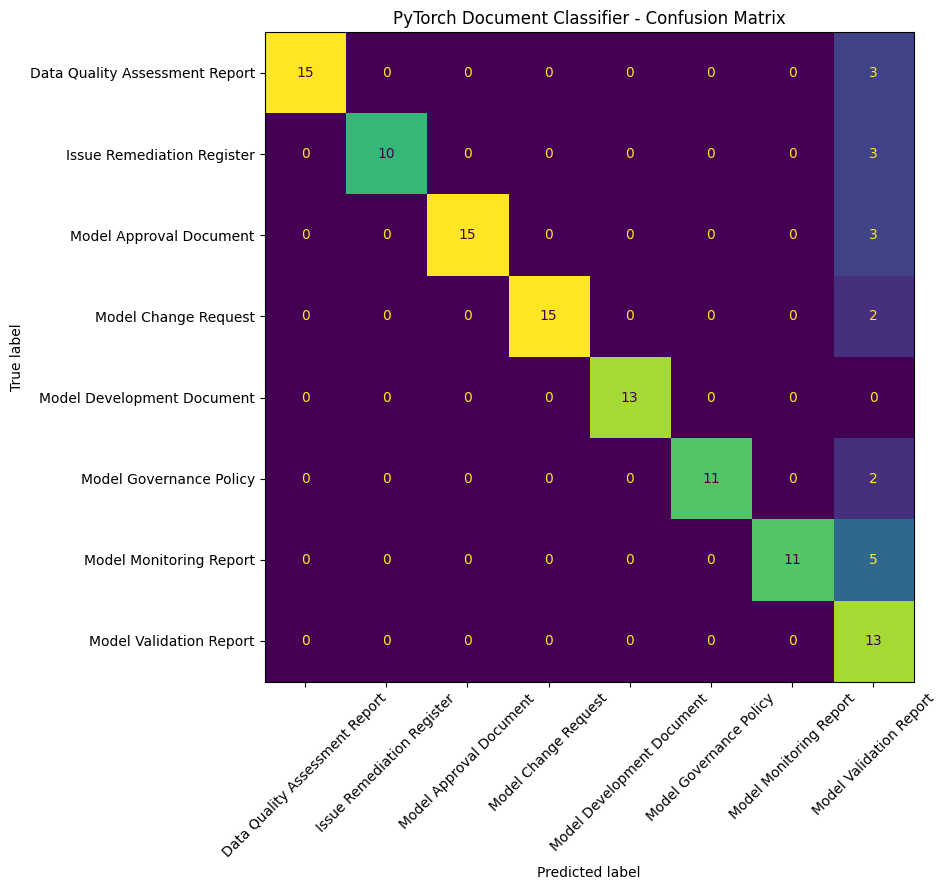

In [ ]:
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=np.arange(number_of_classes)
)

fig, ax = plt.subplots(figsize=(12, 9))

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

display_matrix.plot(
    ax=ax,
    xticks_rotation=45,
    colorbar=False
)

plt.title("PyTorch Document Classifier - Confusion Matrix")
plt.tight_layout()
plt.show()

#Saving the trained model and preprocessing objects

In [ ]:
torch.save(
    {
        "model_state_dict": pytorch_classifier.state_dict(),
        "input_dimension": input_dimension,
        "number_of_classes": number_of_classes,
        "class_names": label_encoder.classes_.tolist(),
        "embedding_features": "TF-IDF",
        "random_state": RANDOM_STATE
    },
    MODEL_DIR / "document_classifier_pytorch.pt"
)

joblib.dump(
    tfidf_vectorizer,
    MODEL_DIR / "document_tfidf_vectorizer.pkl"
)

joblib.dump(
    label_encoder,
    MODEL_DIR / "document_label_encoder.pkl"
)

training_history_df = pd.DataFrame(training_history)

training_history_df.to_csv(
    PROCESSED_DIR / "document_classifier_training_history.csv",
    index=False
)

print("PyTorch model and preprocessing objects saved.")

PyTorch model and preprocessing objects saved.


#NLP BASED CONTRADICTION DETECTION

#Install and load the NLI Model

In [ ]:
!pip -q install transformers sentencepiece

In [ ]:
import torch
import pandas as pd
import numpy as np

from transformers import AutoTokenizer, AutoModelForSequenceClassification

NLI_MODEL_NAME = "cross-encoder/nli-deberta-v3-small"

nli_tokenizer = AutoTokenizer.from_pretrained(NLI_MODEL_NAME)

nli_model = AutoModelForSequenceClassification.from_pretrained(
    NLI_MODEL_NAME
).to(DEVICE)

nli_model.eval()

id2label = nli_model.config.id2label

print("NLI model loaded:", NLI_MODEL_NAME)
print("Model label mapping:", id2label)

config.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.35k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  568MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

NLI model loaded: cross-encoder/nli-deberta-v3-small
Model label mapping: {0: 'contradiction', 1: 'entailment', 2: 'neutral'}


#Creating controlled credit risk contradiction examples

In [ ]:
claim_pairs = pd.DataFrame([
    {
        "model_id": "TEST-PD-001",
        "claim_type": "PD_HORIZON",
        "premise": "The probability of default model estimates default risk over a 12-month horizon.",
        "hypothesis": "The probability of default model estimates default risk over a 24-month horizon.",
        "expected_relationship": "contradiction"
    },
    {
        "model_id": "TEST-PD-002",
        "claim_type": "PD_METHODOLOGY",
        "premise": "The probability of default model uses logistic regression for parameter estimation.",
        "hypothesis": "The probability of default model uses logistic regression for parameter estimation.",
        "expected_relationship": "entailment"
    },
    {
        "model_id": "TEST-LGD-001",
        "claim_type": "LGD_METHODOLOGY",
        "premise": "The LGD model estimates loss severity using discounted recovery cash flows.",
        "hypothesis": "The LGD model estimates loss severity using collateral recovery data.",
        "expected_relationship": "neutral"
    },
    {
        "model_id": "TEST-EAD-001",
        "claim_type": "EAD_METHODOLOGY",
        "premise": "The EAD model estimates exposure using a credit conversion factor for undrawn commitments.",
        "hypothesis": "The EAD model does not use credit conversion factors for undrawn commitments.",
        "expected_relationship": "contradiction"
    },
    {
        "model_id": "TEST-PD-003",
        "claim_type": "DEFAULT_DEFINITION",
        "premise": "The model defines default using a 90 days past due threshold.",
        "hypothesis": "The model defines default using a 90 days past due threshold and unlikeliness to pay criteria.",
        "expected_relationship": "entailment"
    }
])

display(claim_pairs)

,model_id,claim_type,premise,hypothesis,expected_relationship
0,TEST-PD-001,PD_HORIZON,The probability of default model estimates def...,The probability of default model estimates def...,contradiction
1,TEST-PD-002,PD_METHODOLOGY,The probability of default model uses logistic...,The probability of default model uses logistic...,entailment
2,TEST-LGD-001,LGD_METHODOLOGY,The LGD model estimates loss severity using di...,The LGD model estimates loss severity using co...,neutral
3,TEST-EAD-001,EAD_METHODOLOGY,The EAD model estimates exposure using a credi...,The EAD model does not use credit conversion f...,contradiction
4,TEST-PD-003,DEFAULT_DEFINITION,The model defines default using a 90 days past...,The model defines default using a 90 days past...,entailment


#Runing the NLI inference engine

In [ ]:
def classify_nli_relationship(premise, hypothesis):

    inputs = nli_tokenizer(
        premise,
        hypothesis,
        return_tensors="pt",
        truncation=True,
        max_length=256
    )

    inputs = {
        key: value.to(DEVICE)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = nli_model(**inputs)

        probabilities = torch.softmax(
            outputs.logits,
            dim=1
        )[0]

    predicted_index = int(torch.argmax(probabilities).item())

    predicted_label = str(
        id2label[predicted_index]
    ).lower()

    confidence = float(
        probabilities[predicted_index].item()
    )

    return predicted_label, confidence


nli_results = []

for _, row in claim_pairs.iterrows():

    predicted_label, confidence = classify_nli_relationship(
        row["premise"],
        row["hypothesis"]
    )

    nli_results.append({
        **row.to_dict(),
        "predicted_relationship": predicted_label,
        "prediction_confidence": round(confidence, 4),
        "nli_model": NLI_MODEL_NAME,
        "review_status": "PENDING_HUMAN_REVIEW"
    })


nli_results_df = pd.DataFrame(nli_results)

display(
    nli_results_df[
        [
            "model_id",
            "claim_type",
            "expected_relationship",
            "predicted_relationship",
            "prediction_confidence"
        ]
    ]
)

,model_id,claim_type,expected_relationship,predicted_relationship,prediction_confidence
0,TEST-PD-001,PD_HORIZON,contradiction,contradiction,0.9949
1,TEST-PD-002,PD_METHODOLOGY,entailment,entailment,0.9899
2,TEST-LGD-001,LGD_METHODOLOGY,neutral,contradiction,0.9867
3,TEST-EAD-001,EAD_METHODOLOGY,contradiction,contradiction,0.9995
4,TEST-PD-003,DEFAULT_DEFINITION,entailment,neutral,0.9992


#Identify potential contradictions

In [ ]:
contradiction_labels = [
    label for label in id2label.values()
    if "contradiction" in str(label).lower()
]

if not contradiction_labels:
    raise ValueError(
        "The NLI model's label mapping does not expose a "
        "contradiction label. Inspect id2label before proceeding."
    )

contradiction_label = str(
    contradiction_labels[0]
).lower()

nli_results_df["potential_contradiction"] = (
    nli_results_df["predicted_relationship"].str.lower()
    == contradiction_label
)

nli_results_df["finding_status"] = np.where(
    nli_results_df["potential_contradiction"],
    "POTENTIAL_CONTRADICTION",
    "NO_CONTRADICTION_FLAG"
)

display(
    nli_results_df[
        [
            "model_id",
            "claim_type",
            "predicted_relationship",
            "prediction_confidence",
            "finding_status"
        ]
    ]
)

,model_id,claim_type,predicted_relationship,prediction_confidence,finding_status
0,TEST-PD-001,PD_HORIZON,contradiction,0.9949,POTENTIAL_CONTRADICTION
1,TEST-PD-002,PD_METHODOLOGY,entailment,0.9899,NO_CONTRADICTION_FLAG
2,TEST-LGD-001,LGD_METHODOLOGY,contradiction,0.9867,POTENTIAL_CONTRADICTION
3,TEST-EAD-001,EAD_METHODOLOGY,contradiction,0.9995,POTENTIAL_CONTRADICTION
4,TEST-PD-003,DEFAULT_DEFINITION,neutral,0.9992,NO_CONTRADICTION_FLAG


#Evaluate controlled NLI values

In [ ]:
nli_results_df["expected_relationship"] = (
    nli_results_df["expected_relationship"].str.lower()
)

nli_results_df["prediction_correct"] = (
    nli_results_df["expected_relationship"]
    == nli_results_df["predicted_relationship"].str.lower()
)

print("Controlled NLI test results:")
display(
    nli_results_df[
        [
            "model_id",
            "expected_relationship",
            "predicted_relationship",
            "prediction_correct"
        ]
    ]
)

print(
    "Controlled example accuracy:",
    round(nli_results_df["prediction_correct"].mean(), 4)
)

nli_results_df.to_csv(
    PROCESSED_DIR / "nli_contradiction_test_results.csv",
    index=False
)

Controlled NLI test results:


,model_id,expected_relationship,predicted_relationship,prediction_correct
0,TEST-PD-001,contradiction,contradiction,True
1,TEST-PD-002,entailment,entailment,True
2,TEST-LGD-001,neutral,contradiction,False
3,TEST-EAD-001,contradiction,contradiction,True
4,TEST-PD-003,entailment,neutral,False


Controlled example accuracy: 0.6


#Generating document classification prediction

In [ ]:
test_classification_results = classification_df.iloc[
    test_idx
][
    ["model_id", "document_type", "file_name"]
].copy()

test_classification_results["predicted_document_type"] = (
    label_encoder.inverse_transform(test_predictions)
)

test_classification_results["prediction_confidence"] = (
    test_probabilities.max(axis=1)
)

test_classification_results["prediction_correct"] = (
    test_classification_results["document_type"]
    == test_classification_results["predicted_document_type"]
)

test_classification_results["review_status"] = "PENDING_REVIEW"

test_classification_results.to_csv(
    PROCESSED_DIR / "document_classification_predictions.csv",
    index=False
)

display(test_classification_results.head(20))

,model_id,document_type,file_name,predicted_document_type,prediction_confidence,prediction_correct,review_status
0,CR-EAD-001,Model Development Document,CR-EAD-001_Model_Development_Document.txt,Model Development Document,0.999978,True,PENDING_REVIEW
1,CR-EAD-001,Model Validation Report,CR-EAD-001_Model_Validation_Report.txt,Model Validation Report,0.999162,True,PENDING_REVIEW
2,CR-EAD-001,Model Monitoring Report,CR-EAD-001_Model_Monitoring_Report.txt,Model Validation Report,0.193066,False,PENDING_REVIEW
3,CR-EAD-001,Model Approval Document,CR-EAD-001_Model_Approval_Document.txt,Model Approval Document,0.998568,True,PENDING_REVIEW
4,CR-EAD-001,Data Quality Assessment Report,CR-EAD-001_Data_Quality_Assessment_Report.txt,Data Quality Assessment Report,0.998645,True,PENDING_REVIEW
37,CR-PD-007,Model Governance Policy,CR-PD-007_Model_Governance_Policy.txt,Model Governance Policy,0.998446,True,PENDING_REVIEW
38,CR-PD-007,Model Approval Document,CR-PD-007_Model_Approval_Document.txt,Model Approval Document,0.998568,True,PENDING_REVIEW
39,CR-PD-007,Data Quality Assessment Report,CR-PD-007_Data_Quality_Assessment_Report.txt,Model Validation Report,0.193066,False,PENDING_REVIEW
40,CR-PD-007,Model Change Request,CR-PD-007_Model_Change_Request.txt,Model Validation Report,0.193066,False,PENDING_REVIEW
41,CR-PD-007,Issue Remediation Register,CR-PD-007_Issue_Remediation_Register.txt,Model Validation Report,0.193066,False,PENDING_REVIEW


#Creating the model performance reports

In [ ]:
performance_report = {
    "project": "ModelGuard AI",
    "phase": "Phase 5",
    "evaluation_date": pd.Timestamp.now(tz="UTC").isoformat(),
    "training_documents": int(len(train_idx)),
    "validation_documents": int(len(val_idx)),
    "testing_documents": int(len(test_idx)),
    "unique_model_groups": int(classification_df["model_id"].nunique()),
    "document_categories": int(number_of_classes),
    "baseline_accuracy": float(baseline_accuracy),
    "baseline_macro_f1": float(baseline_f1),
    "pytorch_accuracy": float(pytorch_accuracy),
    "pytorch_macro_precision": float(pytorch_precision),
    "pytorch_macro_recall": float(pytorch_recall),
    "pytorch_macro_f1": float(pytorch_f1),
    "classifier": "TF-IDF + PyTorch MLP",
    "nli_model": NLI_MODEL_NAME,
    "evaluation_type": "Synthetic prototype evaluation",
    "production_approved": False
}

with open(
    PROCESSED_DIR / "phase5_model_performance_report.json",
    "w"
) as file:
    json.dump(performance_report, file, indent=4)

print(json.dumps(performance_report, indent=4))

{
    "project": "ModelGuard AI",
    "phase": "Phase 5",
    "evaluation_date": "2026-11-17T12:56:25.359151+00:00",
    "training_documents": 381,
    "validation_documents": 99,
    "testing_documents": 121,
    "unique_model_groups": 100,
    "document_categories": 8,
    "baseline_accuracy": 0.8512396694214877,
    "baseline_macro_f1": 0.8684547009954618,
    "pytorch_accuracy": 0.8512396694214877,
    "pytorch_macro_precision": 0.9274193548387097,
    "pytorch_macro_recall": 0.8564880279034691,
    "pytorch_macro_f1": 0.8684547009954618,
    "classifier": "TF-IDF + PyTorch MLP",
    "nli_model": "cross-encoder/nli-deberta-v3-small",
    "evaluation_type": "Synthetic prototype evaluation",
    "production_approved": false
}


#Visualising training and validation loss

In [ ]:
training_history_df = pd.DataFrame(training_history)

fig = px.line(
    training_history_df,
    x="epoch",
    y=["train_loss", "validation_loss"],
    markers=True,
    title="PyTorch Document Classifier - Training History"
)

fig.update_layout(
    xaxis_title="Epoch",
    yaxis_title="Cross-Entropy Loss",
    legend_title="Loss Type"
)

fig.show()

#ENVIRONMENT AND VALIDATION CONFIRMATION

#Import Validation Libraries

In [ ]:
!pip -q install scipy scikit-learn statsmodels

In [9]:
from google.colab import drive
import os
import shutil

try:
    # Unmount if there is any stale mount
    !usr/bin/fusermount -u /content/drive
except Exception:
    pass

# If the directory exists and is not empty, clear it out to allow mounting
if os.path.exists('/content/drive') and os.listdir('/content/drive'):
    print("Cleaning up existing files in /content/drive mountpoint...")
    try:
        shutil.rmtree('/content/drive')
    except Exception as e:
        print(f"Warning during cleanup: {e}")

try:
    # Mount Google Drive cleanly
    drive.mount('/content/drive', force_remount=True)
    print("Google Drive successfully mounted!")
except Exception as e:
    print(f"Error mounting Google Drive: {e}")

/bin/bash: line 1: usr/bin/fusermount: No such file or directory
Cleaning up existing files in /content/drive mountpoint...
Mounted at /content/drive
Google Drive successfully mounted!


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import json
import hashlib

from pathlib import Path
from datetime import datetime, timezone

from scipy.stats import ks_2samp
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    brier_score_loss,
    log_loss,
    mean_absolute_error,
    mean_squared_error
)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

PROJECT_ROOT = Path("/content/drive/MyDrive/ModelGuard_AI")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
SYNTHETIC_DIR = PROJECT_ROOT / "data" / "synthetic"
VALIDATION_DIR = PROJECT_ROOT / "reports" / "validation"

SYNTHETIC_DIR.mkdir(parents=True, exist_ok=True)
VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

model_inventory = pd.read_csv(
    PROCESSED_DIR / "model_inventory.csv"
)

print("Validation environment initialised.")
print("Model inventory records:", len(model_inventory))

Validation environment initialised.
Model inventory records: 100


#Define validation threshold and methodology

In [11]:
VALIDATION_CONFIG = {
    "framework_version": "1.0",
    "evaluation_type": "Synthetic prototype",
    "as_of_date": datetime.now(timezone.utc).date().isoformat(),

    "PD": {
        "minimum_auc": 0.65,
        "minimum_gini": 0.30,
        "maximum_brier_score": 0.10,
        "maximum_oe_deviation": 0.20
    },

    "LGD": {
        "maximum_mae": 0.15,
        "maximum_rmse": 0.20,
        "maximum_absolute_bias": 0.05
    },

    "EAD": {
        "maximum_mae_relative": 0.15,
        "maximum_rmse_relative": 0.20,
        "maximum_absolute_ccf_bias": 0.10
    }
}

with open(
    PROJECT_ROOT / "config" / "validation_thresholds.json",
    "w"
) as f:
    json.dump(VALIDATION_CONFIG, f, indent=4)

print(json.dumps(VALIDATION_CONFIG, indent=4))

{
    "framework_version": "1.0",
    "evaluation_type": "Synthetic prototype",
    "as_of_date": "2026-11-17",
    "PD": {
        "minimum_auc": 0.65,
        "minimum_gini": 0.3,
        "maximum_brier_score": 0.1,
        "maximum_oe_deviation": 0.2
    },
    "LGD": {
        "maximum_mae": 0.15,
        "maximum_rmse": 0.2,
        "maximum_absolute_bias": 0.05
    },
    "EAD": {
        "maximum_mae_relative": 0.15,
        "maximum_rmse_relative": 0.2,
        "maximum_absolute_ccf_bias": 0.1
    }
}


#Identifying representative PD, LGD and EAD models

In [12]:
model_inventory["model_type"] = (
    model_inventory["model_type"].astype(str).str.upper()
)

representative_models = {}

for model_type in ["PD", "LGD", "EAD"]:

    candidates = model_inventory[
        model_inventory["model_type"] == model_type
    ]

    if candidates.empty:
        raise ValueError(
            f"No {model_type} model found in the model inventory."
        )

    selected = candidates.iloc[0]

    representative_models[model_type] = {
        "model_id": selected["model_id"],
        "model_name": selected["model_name"]
    }

print(json.dumps(representative_models, indent=4))

{
    "PD": {
        "model_id": "CR-PD-003",
        "model_name": "PD Risk Model 003"
    },
    "LGD": {
        "model_id": "CR-LGD-006",
        "model_name": "LGD Risk Model 006"
    },
    "EAD": {
        "model_id": "CR-EAD-001",
        "model_name": "EAD Risk Model 001"
    }
}


#GENERATING SYNTHETIC CREDIT RISK DATASETS

#Generate PD Validation data

In [13]:
N_PD = 8000

observation_dates = pd.date_range(
    start="2024-01-01",
    periods=36,
    freq="MS"
)

date_index = rng.integers(
    0, len(observation_dates), N_PD
)

pd_dates = observation_dates[date_index]

risk_score = rng.beta(2.2, 2.0, N_PD)

# Illustrative macroeconomic cycle indicator.
macro_index = (
    0.35 * np.sin(2 * np.pi * date_index / 36)
    + rng.normal(0, 0.10, N_PD)
)

def sigmoid(x):
    return 1 / (1 + np.exp(-x))


# TTC PD reflects structural borrower risk.
pd_ttc = sigmoid(
    -4.5 + 2.1 * risk_score
)

# PIT PD incorporates cyclical macroeconomic conditions.
pd_pit = sigmoid(
    -4.5 + 2.1 * risk_score + 0.8 * macro_index
)

# Illustrative model bias for validation testing.
predicted_pd_pit = np.clip(
    pd_pit * 1.10 + 0.003,
    0.0001,
    0.9999
)

default_flag = rng.binomial(
    1,
    pd_pit
)

pd_validation_data = pd.DataFrame({
    "model_id": representative_models["PD"]["model_id"],
    "observation_id": [
        f"PD-OBS-{i:06d}" for i in range(1, N_PD + 1)
    ],
    "observation_date": pd_dates,
    "risk_score": risk_score,
    "macro_index": macro_index,
    "pd_ttc": pd_ttc,
    "pd_pit": pd_pit,
    "predicted_pd_pit": predicted_pd_pit,
    "default_flag": default_flag
})

pd_validation_data.to_csv(
    SYNTHETIC_DIR / "pd_validation_dataset.csv",
    index=False
)

print("PD observations:", len(pd_validation_data))
print("Default rate:", round(pd_validation_data["default_flag"].mean(), 4))
display(pd_validation_data.head())

PD observations: 8000
Default rate: 0.0352


,model_id,observation_id,observation_date,risk_score,macro_index,pd_ttc,pd_pit,predicted_pd_pit,default_flag
0,CR-PD-003,PD-OBS-000001,2024-04-01,0.159239,0.138131,0.015283,0.017039,0.021742,0
1,CR-PD-003,PD-OBS-000002,2026-04-01,0.911202,-0.304661,0.070014,0.055714,0.064285,0
2,CR-PD-003,PD-OBS-000003,2025-12-01,0.426925,-0.113017,0.026508,0.024272,0.029699,0
3,CR-PD-003,PD-OBS-000004,2025-04-01,0.793312,0.129284,0.055512,0.061191,0.070310,0
4,CR-PD-003,PD-OBS-000005,2025-04-01,0.393060,0.114991,0.024733,0.027052,0.032757,0


#Generating LGD validation data

In [14]:
N_LGD = 4000

lgd_ead = rng.lognormal(
    mean=11.0,
    sigma=0.65,
    size=N_LGD
)

secured_flag = rng.binomial(
    1,
    0.60,
    N_LGD
)

collateral_coverage = np.clip(
    rng.beta(2.0, 2.5, N_LGD) * secured_flag,
    0,
    1.5
)

# Expected LGD based on underlying portfolio characteristics.
latent_lgd = np.clip(
    0.65
    - 0.30 * collateral_coverage
    - 0.08 * secured_flag
    + 0.06 * (1 - collateral_coverage),
    0.02,
    0.98
)

# Realised LGD includes outcome uncertainty.
realised_lgd = np.clip(
    latent_lgd + rng.normal(0, 0.12, N_LGD),
    0,
    1
)

# Model estimates contain an illustrative downward bias.
predicted_lgd = np.clip(
    latent_lgd - 0.03 + rng.normal(0, 0.07, N_LGD),
    0,
    1
)

recovery_amount = lgd_ead * (1 - realised_lgd)

recovery_cost = recovery_amount * rng.uniform(
    0.01,
    0.08,
    N_LGD
)

recovery_period_years = rng.uniform(
    0.2,
    4.0,
    N_LGD
)

discount_rate = rng.uniform(
    0.04,
    0.12,
    N_LGD
)

discounted_net_recovery = (
    recovery_amount - recovery_cost
) / (
    (1 + discount_rate) ** recovery_period_years
)

realised_lgd_discounted = np.clip(
    1 - discounted_net_recovery / lgd_ead,
    0,
    1
)

lgd_validation_data = pd.DataFrame({
    "model_id": representative_models["LGD"]["model_id"],
    "observation_id": [
        f"LGD-OBS-{i:06d}" for i in range(1, N_LGD + 1)
    ],
    "ead": lgd_ead,
    "secured_flag": secured_flag,
    "collateral_coverage": collateral_coverage,
    "recovery_amount": recovery_amount,
    "recovery_cost": recovery_cost,
    "recovery_period_years": recovery_period_years,
    "discount_rate": discount_rate,
    "realised_lgd": realised_lgd_discounted,
    "predicted_lgd": predicted_lgd
})

lgd_validation_data.to_csv(
    SYNTHETIC_DIR / "lgd_validation_dataset.csv",
    index=False
)

print("LGD observations:", len(lgd_validation_data))
print(
    "Average realised LGD:",
    round(lgd_validation_data["realised_lgd"].mean(), 4)
)

display(lgd_validation_data.head())

LGD observations: 4000
Average realised LGD: 0.6462


,model_id,observation_id,ead,secured_flag,collateral_coverage,recovery_amount,recovery_cost,recovery_period_years,discount_rate,realised_lgd,predicted_lgd
0,CR-LGD-006,LGD-OBS-000001,41688.502356,1,0.316822,14125.266054,1042.023840,1.794584,0.076682,0.725137,0.502591
1,CR-LGD-006,LGD-OBS-000002,80241.718609,1,0.461773,41312.221548,1093.961706,2.322911,0.097091,0.595849,0.336368
2,CR-LGD-006,LGD-OBS-000003,18951.990745,1,0.549910,10554.454487,683.839584,2.542139,0.040546,0.529229,0.404381
3,CR-LGD-006,LGD-OBS-000004,22596.606235,1,0.217287,8406.708283,380.340049,0.269354,0.064492,0.650727,0.518970
4,CR-LGD-006,LGD-OBS-000005,204347.607801,1,0.547620,131542.184668,1809.203486,1.773809,0.106817,0.469728,0.359859


#Generating EAD Validation data

In [15]:
N_EAD = 4000

credit_limit = rng.lognormal(
    mean=11.5,
    sigma=0.65,
    size=N_EAD
)

utilisation = rng.uniform(
    0.10,
    0.95,
    N_EAD
)

drawn_amount = credit_limit * utilisation

undrawn_commitment = credit_limit - drawn_amount

# Latent CCF varies with utilisation.
latent_ccf = np.clip(
    0.35 + 0.25 * utilisation,
    0.05,
    0.95
)

# Observed CCF includes random variation.
observed_ccf = np.clip(
    latent_ccf + rng.normal(0, 0.12, N_EAD),
    0,
    1
)

# Model CCF has an illustrative upward bias.
predicted_ccf = np.clip(
    latent_ccf + 0.04 + rng.normal(0, 0.06, N_EAD),
    0,
    1
)

realised_ead = (
    drawn_amount
    + observed_ccf * undrawn_commitment
)

predicted_ead = (
    drawn_amount
    + predicted_ccf * undrawn_commitment
)

ead_validation_data = pd.DataFrame({
    "model_id": representative_models["EAD"]["model_id"],
    "observation_id": [
        f"EAD-OBS-{i:06d}" for i in range(1, N_EAD + 1)
    ],
    "credit_limit": credit_limit,
    "drawn_amount": drawn_amount,
    "undrawn_commitment": undrawn_commitment,
    "utilisation": utilisation,
    "observed_ccf": observed_ccf,
    "predicted_ccf": predicted_ccf,
    "realised_ead": realised_ead,
    "predicted_ead": predicted_ead
})

ead_validation_data.to_csv(
    SYNTHETIC_DIR / "ead_validation_dataset.csv",
    index=False
)

print("EAD observations:", len(ead_validation_data))
print(
    "Average observed CCF:",
    round(ead_validation_data["observed_ccf"].mean(), 4)
)

display(ead_validation_data.head())

EAD observations: 4000
Average observed CCF: 0.4818


,model_id,observation_id,credit_limit,drawn_amount,undrawn_commitment,utilisation,observed_ccf,predicted_ccf,realised_ead,predicted_ead
0,CR-EAD-001,EAD-OBS-000001,170925.317138,36927.982716,133997.334421,0.216047,0.305630,0.356495,77881.573884,84697.306004
1,CR-EAD-001,EAD-OBS-000002,85591.071370,58126.803259,27464.268111,0.679122,0.446292,0.477029,70383.891940,71228.060072
2,CR-EAD-001,EAD-OBS-000003,102153.858238,55800.137969,46353.720269,0.546236,0.592657,0.485604,83272.011340,78309.690838
3,CR-EAD-001,EAD-OBS-000004,44045.787338,30636.303192,13409.484146,0.695556,0.518909,0.469351,37594.604937,36930.064336
4,CR-EAD-001,EAD-OBS-000005,108088.955175,27494.386014,80594.569161,0.254368,0.496480,0.563954,67507.955409,72945.993751


#DATA QUALITY AND VALIDATION CHECKS

#Validating the three datasets

In [16]:
pd_validation_data = pd.read_csv(
    SYNTHETIC_DIR / "pd_validation_dataset.csv"
)

lgd_validation_data = pd.read_csv(
    SYNTHETIC_DIR / "lgd_validation_dataset.csv"
)

ead_validation_data = pd.read_csv(
    SYNTHETIC_DIR / "ead_validation_dataset.csv"
)

def run_data_quality_checks(df, name, required_columns):

    results = []

    for column in required_columns:

        results.append({
            "dataset": name,
            "check": f"{column}_not_null",
            "result": bool(df[column].notna().all())
        })

    results.extend([
        {
            "dataset": name,
            "check": "unique_observation_ids",
            "result": bool(df["observation_id"].is_unique)
        },
        {
            "dataset": name,
            "check": "no_duplicate_rows",
            "result": bool(not df.duplicated().any())
        }
    ])

    return results


quality_results = []

quality_results += run_data_quality_checks(
    pd_validation_data,
    "PD",
    [
        "model_id", "observation_id", "pd_ttc",
        "pd_pit", "predicted_pd_pit", "default_flag"
    ]
)

quality_results += run_data_quality_checks(
    lgd_validation_data,
    "LGD",
    [
        "model_id", "observation_id", "ead",
        "realised_lgd", "predicted_lgd"
    ]
)

quality_results += run_data_quality_checks(
    ead_validation_data,
    "EAD",
    [
        "model_id", "observation_id", "drawn_amount",
        "undrawn_commitment", "realised_ead", "predicted_ead"
    ]
)

quality_df = pd.DataFrame(quality_results)

display(quality_df)

assert quality_df["result"].all(), (
    "One or more data quality checks failed."
)

assert pd_validation_data["default_flag"].isin([0, 1]).all()
assert pd_validation_data["predicted_pd_pit"].between(0, 1).all()

assert lgd_validation_data["realised_lgd"].between(0, 1).all()
assert lgd_validation_data["predicted_lgd"].between(0, 1).all()

assert ead_validation_data["predicted_ead"].ge(0).all()
assert ead_validation_data["realised_ead"].ge(0).all()

quality_df.to_csv(
    PROCESSED_DIR / "credit_risk_data_quality_results.csv",
    index=False
)

print("All initial data quality checks passed.")

,dataset,check,result
0,PD,model_id_not_null,True
1,PD,observation_id_not_null,True
2,PD,pd_ttc_not_null,True
3,PD,pd_pit_not_null,True
4,PD,predicted_pd_pit_not_null,True
5,PD,default_flag_not_null,True
6,PD,unique_observation_ids,True
7,PD,no_duplicate_rows,True
8,LGD,model_id_not_null,True
9,LGD,observation_id_not_null,True


All initial data quality checks passed.


#PD MODEL VALIDATION

#PD discrimination and calibration

In [17]:
# Chronological out-of-time split.
pd_validation_data["observation_date"] = pd.to_datetime(
    pd_validation_data["observation_date"]
)

latest_date = pd_validation_data["observation_date"].max()

cutoff_date = latest_date - pd.DateOffset(months=12)

pd_oot = pd_validation_data[
    pd_validation_data["observation_date"] > cutoff_date
].copy()

if pd_oot["default_flag"].nunique() < 2:
    raise ValueError(
        "The PD out-of-time sample needs both default and non-default cases."
    )

y_true = pd_oot["default_flag"]
y_pred = pd_oot["predicted_pd_pit"]

pd_auc = roc_auc_score(y_true, y_pred)
pd_gini = 2 * pd_auc - 1

default_scores = pd_oot.loc[
    pd_oot["default_flag"] == 1,
    "predicted_pd_pit"
]

non_default_scores = pd_oot.loc[
    pd_oot["default_flag"] == 0,
    "predicted_pd_pit"
]

pd_ks = ks_2samp(
    default_scores,
    non_default_scores
).statistic

pd_brier = brier_score_loss(
    y_true,
    y_pred
)

pd_logloss = log_loss(
    y_true,
    y_pred,
    labels=[0, 1]
)

observed_defaults = int(y_true.sum())
expected_defaults = float(y_pred.sum())

pd_oe_ratio = (
    observed_defaults / expected_defaults
    if expected_defaults > 0 else np.nan
)

pd_oe_deviation = abs(pd_oe_ratio - 1)

pd_metrics = {
    "model_id": representative_models["PD"]["model_id"],
    "validation_type": "OUT_OF_TIME",
    "observation_count": int(len(pd_oot)),
    "default_count": observed_defaults,
    "observed_default_rate": float(y_true.mean()),
    "average_predicted_pd": float(y_pred.mean()),
    "auc": float(pd_auc),
    "gini": float(pd_gini),
    "ks_statistic": float(pd_ks),
    "brier_score": float(pd_brier),
    "log_loss": float(pd_logloss),
    "observed_expected_ratio": float(pd_oe_ratio),
    "oe_deviation": float(pd_oe_deviation)
}

print(json.dumps(pd_metrics, indent=4))

{
    "model_id": "CR-PD-003",
    "validation_type": "OUT_OF_TIME",
    "observation_count": 2611,
    "default_count": 75,
    "observed_default_rate": 0.028724626579854463,
    "average_predicted_pd": 0.0352568927678418,
    "auc": 0.6411671924290221,
    "gini": 0.2823343848580442,
    "ks_statistic": 0.2764353312302839,
    "brier_score": 0.027773588197801798,
    "log_loss": 0.12798011415926708,
    "observed_expected_ratio": 0.81472371286373,
    "oe_deviation": 0.18527628713626998
}


#PD calibration analysis

In [18]:
pd_oot["pd_band"] = pd.qcut(
    pd_oot["predicted_pd_pit"],
    q=10,
    duplicates="drop"
)

pd_calibration = (
    pd_oot
    .groupby("pd_band", observed=True)
    .agg(
        observation_count=("default_flag", "size"),
        average_predicted_pd=("predicted_pd_pit", "mean"),
        observed_default_rate=("default_flag", "mean"),
        observed_defaults=("default_flag", "sum")
    )
    .reset_index()
)

pd_calibration["calibration_difference"] = (
    pd_calibration["observed_default_rate"]
    - pd_calibration["average_predicted_pd"]
)

display(pd_calibration)

fig = px.line(
    pd_calibration,
    x="average_predicted_pd",
    y="observed_default_rate",
    markers=True,
    title="PD Model - Out-of-Time Calibration"
)

fig.add_scatter(
    x=[0, 1],
    y=[0, 1],
    mode="lines",
    name="Perfect Calibration"
)

fig.update_layout(
    xaxis_title="Average Predicted PD",
    yaxis_title="Observed Default Rate"
)

fig.show()

pd_calibration.to_csv(
    PROCESSED_DIR / "pd_calibration_analysis.csv",
    index=False
)

,pd_band,observation_count,average_predicted_pd,observed_default_rate,observed_defaults,calibration_difference
0,"(0.010599999999999998, 0.0186]",262,0.016227,0.022901,6,0.006674
1,"(0.0186, 0.022]",261,0.020183,0.011494,3,-0.008689
2,"(0.022, 0.0254]",261,0.023720,0.007663,2,-0.016057
3,"(0.0254, 0.029]",261,0.027224,0.003831,1,-0.023393
4,"(0.029, 0.0327]",261,0.030840,0.038314,10,0.007474
5,"(0.0327, 0.0369]",261,0.034866,0.019157,5,-0.015709
6,"(0.0369, 0.0418]",260,0.039291,0.038462,10,-0.000829
7,"(0.0418, 0.0477]",262,0.044714,0.041985,11,-0.002729
8,"(0.0477, 0.0561]",261,0.051746,0.061303,16,0.009557
9,"(0.0561, 0.0887]",261,0.063810,0.042146,11,-0.021664


#PD ROC curve

In [19]:
fpr, tpr, thresholds = roc_curve(
    y_true,
    y_pred
)

fig = px.area(
    x=fpr,
    y=tpr,
    title=f"PD Model ROC Curve | AUC = {pd_auc:.4f}",
    labels={
        "x": "False Positive Rate",
        "y": "True Positive Rate"
    }
)

fig.add_scatter(
    x=[0, 1],
    y=[0, 1],
    mode="lines",
    name="Random Classifier"
)

fig.show()

#LGD Model Validation

#LGD Performance Metrics

In [20]:
lgd_actual = lgd_validation_data["realised_lgd"]
lgd_predicted = lgd_validation_data["predicted_lgd"]

lgd_mae = mean_absolute_error(
    lgd_actual,
    lgd_predicted
)

lgd_rmse = np.sqrt(
    mean_squared_error(lgd_actual, lgd_predicted)
)

lgd_bias = float(
    np.mean(lgd_predicted - lgd_actual)
)

lgd_weighted_mae = np.average(
    np.abs(lgd_predicted - lgd_actual),
    weights=lgd_validation_data["ead"]
)

lgd_weighted_bias = np.average(
    lgd_predicted - lgd_actual,
    weights=lgd_validation_data["ead"]
)

lgd_metrics = {
    "model_id": representative_models["LGD"]["model_id"],
    "observation_count": int(len(lgd_validation_data)),
    "average_realised_lgd": float(lgd_actual.mean()),
    "average_predicted_lgd": float(lgd_predicted.mean()),
    "mae": float(lgd_mae),
    "rmse": float(lgd_rmse),
    "bias": float(lgd_bias),
    "ead_weighted_mae": float(lgd_weighted_mae),
    "ead_weighted_bias": float(lgd_weighted_bias)
}

print(json.dumps(lgd_metrics, indent=4))

{
    "model_id": "CR-LGD-006",
    "observation_count": 4000,
    "average_realised_lgd": 0.6462435376254293,
    "average_predicted_lgd": 0.5398019391261378,
    "mae": 0.1380973720417968,
    "rmse": 0.16899831868070891,
    "bias": -0.10644159849929136,
    "ead_weighted_mae": 0.13946832489904623,
    "ead_weighted_bias": -0.10865963485359996
}


#LGD actual versus Predicted analysis

In [21]:
lgd_plot_sample = lgd_validation_data.sample(
    n=min(1000, len(lgd_validation_data)),
    random_state=42
)

fig = px.scatter(
    lgd_plot_sample,
    x="realised_lgd",
    y="predicted_lgd",
    color="secured_flag",
    opacity=0.55,
    title="LGD Model - Actual vs Predicted LGD"
)

fig.add_scatter(
    x=[0, 1],
    y=[0, 1],
    mode="lines",
    name="Perfect Prediction"
)

fig.update_layout(
    xaxis_title="Realised LGD",
    yaxis_title="Predicted LGD"
)

fig.show()

#LGD Performance by collateral segment

In [22]:
lgd_validation_data["collateral_segment"] = pd.cut(
    lgd_validation_data["collateral_coverage"],
    bins=[-0.001, 0.25, 0.50, 0.75, 1.00, 1.50],
    labels=[
        "0-25%",
        "25-50%",
        "50-75%",
        "75-100%",
        "Above 100%"
    ]
)

lgd_segment_analysis = (
    lgd_validation_data
    .groupby("collateral_segment", observed=True)
    .apply(
        lambda group: pd.Series({
            "observations": len(group),
            "average_realised_lgd": group["realised_lgd"].mean(),
            "average_predicted_lgd": group["predicted_lgd"].mean(),
            "mae": mean_absolute_error(
                group["realised_lgd"],
                group["predicted_lgd"]
            )
        })
    )
    .reset_index()
)

display(lgd_segment_analysis)

fig = px.bar(
    lgd_segment_analysis,
    x="collateral_segment",
    y=["average_realised_lgd", "average_predicted_lgd"],
    barmode="group",
    title="LGD - Performance by Collateral Coverage"
)

fig.show()

lgd_segment_analysis.to_csv(
    PROCESSED_DIR / "lgd_segment_analysis.csv",
    index=False
)

/tmp/ipykernel_1978/2774468237.py:16: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



,collateral_segment,observations,average_realised_lgd,average_predicted_lgd,mae
0,0-25%,2151.0,0.733411,0.646372,0.123876
1,25-50%,949.0,0.588344,0.464399,0.150506
2,50-75%,699.0,0.512284,0.383590,0.154160
3,75-100%,201.0,0.452642,0.298594,0.175850


#EAD Model Validation

#EAD Performance Metrics

In [23]:
ead_actual = ead_validation_data["realised_ead"]
ead_predicted = ead_validation_data["predicted_ead"]

ead_mae = mean_absolute_error(
    ead_actual,
    ead_predicted
)

ead_rmse = np.sqrt(
    mean_squared_error(ead_actual, ead_predicted)
)

ead_bias = float(
    np.mean(ead_predicted - ead_actual)
)

ead_relative_mae = (
    ead_mae / ead_actual.mean()
)

ead_relative_rmse = (
    ead_rmse / ead_actual.mean()
)

ccf_bias = float(
    (
        ead_validation_data["predicted_ccf"]
        - ead_validation_data["observed_ccf"]
    ).mean()
)

ead_metrics = {
    "model_id": representative_models["EAD"]["model_id"],
    "observation_count": int(len(ead_validation_data)),
    "average_realised_ead": float(ead_actual.mean()),
    "average_predicted_ead": float(ead_predicted.mean()),
    "mae": float(ead_mae),
    "rmse": float(ead_rmse),
    "bias": float(ead_bias),
    "relative_mae": float(ead_relative_mae),
    "relative_rmse": float(ead_relative_rmse),
    "average_observed_ccf": float(
        ead_validation_data["observed_ccf"].mean()
    ),
    "average_predicted_ccf": float(
        ead_validation_data["predicted_ccf"].mean()
    ),
    "ccf_bias": float(ccf_bias)
}

print(json.dumps(ead_metrics, indent=4))

{
    "model_id": "CR-EAD-001",
    "observation_count": 4000,
    "average_realised_ead": 89210.89891333571,
    "average_predicted_ead": 91556.025097976,
    "mae": 6352.358165677788,
    "rmse": 11013.753175126772,
    "bias": 2345.126184640292,
    "relative_mae": 0.0712060773185215,
    "relative_rmse": 0.1234574845594385,
    "average_observed_ccf": 0.4818281043414444,
    "average_predicted_ccf": 0.5229768597984144,
    "ccf_bias": 0.04114875545696983
}


#EAD Actual vs predicted analysis

In [24]:
ead_plot_sample = ead_validation_data.sample(
    n=min(1000, len(ead_validation_data)),
    random_state=42
)

fig = px.scatter(
    ead_plot_sample,
    x="realised_ead",
    y="predicted_ead",
    color="utilisation",
    opacity=0.55,
    title="EAD Model - Actual vs Predicted Exposure"
)

axis_min = min(
    ead_plot_sample["realised_ead"].min(),
    ead_plot_sample["predicted_ead"].min()
)

axis_max = max(
    ead_plot_sample["realised_ead"].max(),
    ead_plot_sample["predicted_ead"].max()
)

fig.add_scatter(
    x=[axis_min, axis_max],
    y=[axis_min, axis_max],
    mode="lines",
    name="Perfect Prediction"
)

fig.show()

#CCF Performance by utilisation segment

In [25]:
ead_validation_data["utilisation_segment"] = pd.cut(
    ead_validation_data["utilisation"],
    bins=[0, 0.25, 0.50, 0.75, 1.00],
    labels=["0-25%", "25-50%", "50-75%", "75-100%"],
    include_lowest=True
)

ccf_segment_analysis = (
    ead_validation_data
    .groupby("utilisation_segment", observed=True)
    .agg(
        observations=("observation_id", "count"),
        observed_ccf=("observed_ccf", "mean"),
        predicted_ccf=("predicted_ccf", "mean"),
        average_realised_ead=("realised_ead", "mean"),
        average_predicted_ead=("predicted_ead", "mean")
    )
    .reset_index()
)

display(ccf_segment_analysis)

fig = px.bar(
    ccf_segment_analysis,
    x="utilisation_segment",
    y=["observed_ccf", "predicted_ccf"],
    barmode="group",
    title="EAD - Observed vs Predicted CCF by Utilisation"
)

fig.show()

ccf_segment_analysis.to_csv(
    PROCESSED_DIR / "ead_ccf_segment_analysis.csv",
    index=False
)

,utilisation_segment,observations,observed_ccf,predicted_ccf,average_realised_ead,average_predicted_ead
0,0-25%,658,0.396383,0.433558,60484.569536,64419.859846
1,25-50%,1220,0.439746,0.485144,77643.595278,81077.335646
2,50-75%,1164,0.507804,0.547248,96510.606116,98082.269433
3,75-100%,958,0.562545,0.603083,114802.940648,115609.312635


#CONSOLIDATED VALIDATION RESULTS AND FINDINGS

#Consolidated PD, LGD and EAD Metrics

In [26]:
all_validation_metrics = pd.DataFrame([
    {"model_type": "PD", **pd_metrics},
    {"model_type": "LGD", **lgd_metrics},
    {"model_type": "EAD", **ead_metrics}
])

display(all_validation_metrics)

all_validation_metrics.to_csv(
    PROCESSED_DIR / "credit_risk_validation_metrics.csv",
    index=False
)

,model_type,model_id,validation_type,observation_count,default_count,observed_default_rate,average_predicted_pd,auc,gini,ks_statistic,...,bias,ead_weighted_mae,ead_weighted_bias,average_realised_ead,average_predicted_ead,relative_mae,relative_rmse,average_observed_ccf,average_predicted_ccf,ccf_bias
0,PD,CR-PD-003,OUT_OF_TIME,2611,75.0,0.028725,0.035257,0.641167,0.282334,0.276435,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,LGD,CR-LGD-006,NaN,4000,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.106442,0.139468,-0.10866,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,EAD,CR-EAD-001,NaN,4000,NaN,NaN,NaN,NaN,NaN,NaN,...,2345.126185,NaN,NaN,89210.898913,91556.025098,0.071206,0.123457,0.481828,0.522977,0.041149


#Building validation threshold assessment engine

In [27]:
validation_tests = []

def add_validation_test(
    model_type,
    model_id,
    metric_name,
    metric_value,
    threshold,
    direction
):

    if direction == "MIN":
        status = "PASS" if metric_value >= threshold else "THRESHOLD_BREACH"

    elif direction == "MAX":
        status = "PASS" if metric_value <= threshold else "THRESHOLD_BREACH"

    else:
        raise ValueError("Direction must be MIN or MAX")

    validation_tests.append({
        "model_id": model_id,
        "model_type": model_type,
        "metric_name": metric_name,
        "observed_value": float(metric_value),
        "threshold": float(threshold),
        "threshold_direction": direction,
        "test_status": status,
        "assessment_type": "ILLUSTRATIVE_THRESHOLD_TEST",
        "human_review_status": "PENDING_REVIEW"
    })


# PD tests
pd_id = representative_models["PD"]["model_id"]

add_validation_test(
    "PD", pd_id, "AUC", pd_auc,
    VALIDATION_CONFIG["PD"]["minimum_auc"], "MIN"
)

add_validation_test(
    "PD", pd_id, "GINI", pd_gini,
    VALIDATION_CONFIG["PD"]["minimum_gini"], "MIN"
)

add_validation_test(
    "PD", pd_id, "BRIER_SCORE", pd_brier,
    VALIDATION_CONFIG["PD"]["maximum_brier_score"], "MAX"
)

add_validation_test(
    "PD", pd_id, "OE_DEVIATION", pd_oe_deviation,
    VALIDATION_CONFIG["PD"]["maximum_oe_deviation"], "MAX"
)


# LGD tests
lgd_id = representative_models["LGD"]["model_id"]

add_validation_test(
    "LGD", lgd_id, "MAE", lgd_mae,
    VALIDATION_CONFIG["LGD"]["maximum_mae"], "MAX"
)

add_validation_test(
    "LGD", lgd_id, "RMSE", lgd_rmse,
    VALIDATION_CONFIG["LGD"]["maximum_rmse"], "MAX"
)

add_validation_test(
    "LGD", lgd_id, "ABSOLUTE_BIAS", abs(lgd_bias),
    VALIDATION_CONFIG["LGD"]["maximum_absolute_bias"], "MAX"
)


# EAD tests
ead_id = representative_models["EAD"]["model_id"]

add_validation_test(
    "EAD", ead_id, "RELATIVE_MAE", ead_relative_mae,
    VALIDATION_CONFIG["EAD"]["maximum_mae_relative"], "MAX"
)

add_validation_test(
    "EAD", ead_id, "RELATIVE_RMSE", ead_relative_rmse,
    VALIDATION_CONFIG["EAD"]["maximum_rmse_relative"], "MAX"
)

add_validation_test(
    "EAD", ead_id, "ABSOLUTE_CCF_BIAS", abs(ccf_bias),
    VALIDATION_CONFIG["EAD"]["maximum_absolute_ccf_bias"], "MAX"
)


validation_tests_df = pd.DataFrame(validation_tests)

display(validation_tests_df)

validation_tests_df.to_csv(
    PROCESSED_DIR / "credit_risk_validation_test_results.csv",
    index=False
)

,model_id,model_type,metric_name,observed_value,threshold,threshold_direction,test_status,assessment_type,human_review_status
0,CR-PD-003,PD,AUC,0.641167,0.65,MIN,THRESHOLD_BREACH,ILLUSTRATIVE_THRESHOLD_TEST,PENDING_REVIEW
1,CR-PD-003,PD,GINI,0.282334,0.30,MIN,THRESHOLD_BREACH,ILLUSTRATIVE_THRESHOLD_TEST,PENDING_REVIEW
2,CR-PD-003,PD,BRIER_SCORE,0.027774,0.10,MAX,PASS,ILLUSTRATIVE_THRESHOLD_TEST,PENDING_REVIEW
3,CR-PD-003,PD,OE_DEVIATION,0.185276,0.20,MAX,PASS,ILLUSTRATIVE_THRESHOLD_TEST,PENDING_REVIEW
4,CR-LGD-006,LGD,MAE,0.138097,0.15,MAX,PASS,ILLUSTRATIVE_THRESHOLD_TEST,PENDING_REVIEW
5,CR-LGD-006,LGD,RMSE,0.168998,0.20,MAX,PASS,ILLUSTRATIVE_THRESHOLD_TEST,PENDING_REVIEW
6,CR-LGD-006,LGD,ABSOLUTE_BIAS,0.106442,0.05,MAX,THRESHOLD_BREACH,ILLUSTRATIVE_THRESHOLD_TEST,PENDING_REVIEW
7,CR-EAD-001,EAD,RELATIVE_MAE,0.071206,0.15,MAX,PASS,ILLUSTRATIVE_THRESHOLD_TEST,PENDING_REVIEW
8,CR-EAD-001,EAD,RELATIVE_RMSE,0.123457,0.20,MAX,PASS,ILLUSTRATIVE_THRESHOLD_TEST,PENDING_REVIEW
9,CR-EAD-001,EAD,ABSOLUTE_CCF_BIAS,0.041149,0.10,MAX,PASS,ILLUSTRATIVE_THRESHOLD_TEST,PENDING_REVIEW


#Generate validation findings

In [28]:
validation_findings = []

for _, test in validation_tests_df.iterrows():

    if test["test_status"] == "THRESHOLD_BREACH":

        if test["model_type"] == "PD":
            recommendation = (
                "Investigate PD discrimination or calibration performance. "
                "Review segmentation, calibration methodology, default "
                "definition and out-of-time stability."
            )

        elif test["model_type"] == "LGD":
            recommendation = (
                "Investigate LGD estimation error and bias. Review "
                "recovery data, collateral assumptions, workout costs, "
                "discounting and segment-level performance."
            )

        else:
            recommendation = (
                "Investigate EAD and CCF estimation error. Review "
                "undrawn exposure, utilisation, drawdown behaviour "
                "and facility segmentation."
            )

        validation_findings.append({
            "finding_id": f"MG-VAL-{len(validation_findings) + 1:05d}",
            "model_id": test["model_id"],
            "model_type": test["model_type"],
            "finding_category": "QUANTITATIVE_VALIDATION",
            "metric_name": test["metric_name"],
            "observed_value": test["observed_value"],
            "threshold": test["threshold"],
            "finding_description": (
                f"{test['metric_name']} breached the configured "
                f"prototype threshold."
            ),
            "recommended_action": recommendation,
            "severity": "MEDIUM",
            "review_status": "PENDING_REVIEW",
            "remediation_status": "OPEN",
            "assessment_type": "SYNTHETIC_PROTOTYPE"
        })


validation_findings_df = pd.DataFrame(validation_findings)

if validation_findings_df.empty:
    validation_findings_df = pd.DataFrame(columns=[
        "finding_id", "model_id", "model_type",
        "finding_category", "metric_name",
        "observed_value", "threshold",
        "finding_description", "recommended_action",
        "severity", "review_status", "remediation_status",
        "assessment_type"
    ])

validation_findings_df.to_csv(
    PROCESSED_DIR / "credit_risk_validation_findings.csv",
    index=False
)

print("Potential validation findings:", len(validation_findings_df))
display(validation_findings_df)

Potential validation findings: 3


,finding_id,model_id,model_type,finding_category,metric_name,observed_value,threshold,finding_description,recommended_action,severity,review_status,remediation_status,assessment_type
0,MG-VAL-00001,CR-PD-003,PD,QUANTITATIVE_VALIDATION,AUC,0.641167,0.65,AUC breached the configured prototype threshold.,Investigate PD discrimination or calibration p...,MEDIUM,PENDING_REVIEW,OPEN,SYNTHETIC_PROTOTYPE
1,MG-VAL-00002,CR-PD-003,PD,QUANTITATIVE_VALIDATION,GINI,0.282334,0.30,GINI breached the configured prototype threshold.,Investigate PD discrimination or calibration p...,MEDIUM,PENDING_REVIEW,OPEN,SYNTHETIC_PROTOTYPE
2,MG-VAL-00003,CR-LGD-006,LGD,QUANTITATIVE_VALIDATION,ABSOLUTE_BIAS,0.106442,0.05,ABSOLUTE_BIAS breached the configured prototyp...,Investigate LGD estimation error and bias. Rev...,MEDIUM,PENDING_REVIEW,OPEN,SYNTHETIC_PROTOTYPE


#Creating model level validation summary

In [29]:
model_validation_summary = (
    validation_tests_df
    .groupby(["model_id", "model_type"])
    .agg(
        total_tests=("metric_name", "count"),
        passed_tests=(
            "test_status",
            lambda x: (x == "PASS").sum()
        ),
        threshold_breaches=(
            "test_status",
            lambda x: (x == "THRESHOLD_BREACH").sum()
        )
    )
    .reset_index()
)

model_validation_summary["test_pass_rate"] = (
    model_validation_summary["passed_tests"]
    / model_validation_summary["total_tests"]
) * 100

model_validation_summary["overall_assessment"] = np.where(
    model_validation_summary["threshold_breaches"] > 0,
    "REVIEW_REQUIRED",
    "NO_CONFIGURED_THRESHOLD_BREACH"
)

display(model_validation_summary)

model_validation_summary.to_csv(
    PROCESSED_DIR / "model_validation_summary.csv",
    index=False
)

,model_id,model_type,total_tests,passed_tests,threshold_breaches,test_pass_rate,overall_assessment
0,CR-EAD-001,EAD,3,3,0,100.000000,NO_CONFIGURED_THRESHOLD_BREACH
1,CR-LGD-006,LGD,3,2,1,66.666667,REVIEW_REQUIRED
2,CR-PD-003,PD,4,2,2,50.000000,REVIEW_REQUIRED


#Visualising validation result

In [30]:
fig = px.bar(
    validation_tests_df,
    x="metric_name",
    y="observed_value",
    color="test_status",
    facet_col="model_type",
    facet_col_wrap=1,
    title="ModelGuard AI - Credit Risk Validation Results",
    hover_data=["threshold", "model_id"]
)

fig.update_layout(
    height=900,
    xaxis_title="Validation Metric",
    yaxis_title="Observed Value"
)

fig.show()

#Generating validation report

In [31]:
phase6_report = {
    "project": "ModelGuard AI",
    "phase": "Phase 6 - Credit Risk Model Validation",
    "generated_at": datetime.now(timezone.utc).isoformat(),
    "validation_configuration_version": VALIDATION_CONFIG["framework_version"],
    "evaluation_type": "Synthetic prototype",
    "representative_models": representative_models,

    "datasets": {
        "PD": len(pd_validation_data),
        "LGD": len(lgd_validation_data),
        "EAD": len(ead_validation_data)
    },

    "validation_metrics": {
        "PD": pd_metrics,
        "LGD": lgd_metrics,
        "EAD": ead_metrics
    },

    "validation_test_count": int(len(validation_tests_df)),
    "threshold_breach_count": int(
        (validation_tests_df["test_status"] == "THRESHOLD_BREACH").sum()
    ),
    "potential_finding_count": int(len(validation_findings_df)),

    "limitations": [
        "Synthetic datasets are not representative of a real bank portfolio.",
        "LGD and EAD observations are not a real out-of-time backtesting sample.",
        "Thresholds are illustrative and require validation governance approval.",
        "No regulatory compliance or model approval conclusion is produced.",
        "Human review is required for all potential findings."
    ],

    "production_approved": False
}

with open(
    VALIDATION_DIR / "phase6_credit_risk_validation_report.json",
    "w"
) as f:
    json.dump(phase6_report, f, indent=4)

print(json.dumps(phase6_report, indent=4))

{
    "project": "ModelGuard AI",
    "phase": "Phase 6 - Credit Risk Model Validation",
    "generated_at": "2026-11-17T17:25:15.747946+00:00",
    "validation_configuration_version": "1.0",
    "evaluation_type": "Synthetic prototype",
    "representative_models": {
        "PD": {
            "model_id": "CR-PD-003",
            "model_name": "PD Risk Model 003"
        },
        "LGD": {
            "model_id": "CR-LGD-006",
            "model_name": "LGD Risk Model 006"
        },
        "EAD": {
            "model_id": "CR-EAD-001",
            "model_name": "EAD Risk Model 001"
        }
    },
    "datasets": {
        "PD": 8000,
        "LGD": 4000,
        "EAD": 4000
    },
    "validation_metrics": {
        "PD": {
            "model_id": "CR-PD-003",
            "validation_type": "OUT_OF_TIME",
            "observation_count": 2611,
            "default_count": 75,
            "observed_default_rate": 0.028724626579854463,
            "average_predicted_pd": 0.0352568

#Final Integrity Checks

In [32]:
assert len(pd_validation_data) == N_PD
assert len(lgd_validation_data) == N_LGD
assert len(ead_validation_data) == N_EAD

assert validation_tests_df["model_id"].notna().all()
assert validation_tests_df["observed_value"].notna().all()

assert validation_tests_df["test_status"].isin(
    ["PASS", "THRESHOLD_BREACH"]
).all()

assert validation_findings_df["review_status"].eq(
    "PENDING_REVIEW"
).all()

assert set(validation_tests_df["model_type"]) == {
    "PD", "LGD", "EAD"
}

print("Phase 6 integrity checks passed.")
print("PD, LGD and EAD validation pipelines executed successfully.")

Phase 6 integrity checks passed.
PD, LGD and EAD validation pipelines executed successfully.
